<a href="https://colab.research.google.com/github/leonIceHot/Computer-Vision-Course/blob/main/CH4_%E5%BD%B1%E5%83%8F%E6%95%B8%E5%AD%B8%E9%81%8B%E7%AE%97.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1.影像算術運算與線性融合 (Arithmetic Operations & Blending)

影像算術運算是對影像像素值進行數學運算的操作，包括：
- ➕ **加法（Addition）**: 調高亮度、多幀平均降噪、影像疊加融合。
- ➖ **減法（Subtraction）**: 調低亮度、背景相減抓移動物體/異物瑕疵。
- ✖️ **乘法（Multiplication）**: 調高對比度、乘上遮罩摳圖 / 聚光燈暗角。
- ➗ **除法（Division）**: 調低對比度、消除光照不均陰影（平場校正） / 鉛筆素描特效。
- 🎭 **混合（Blending）**: 透明度合成

## 1.1 影像四則運算本質（飽和截斷 vs Modulo 溢位）

### ➕ 影像加法（cv2.add）：亮度提升與過曝截斷

- 兩種加法方式

1. **NumPy 加法**: `img1 + img2`
   - 超過255會溢位（模運算）
   - 例如：250 + 10 = 4 (260 % 256)

2. **OpenCV 加法**: `cv2.add(img1, img2)`
   - 超過255會截斷為255（飽和運算）
   - 例如：250 + 10 = 255

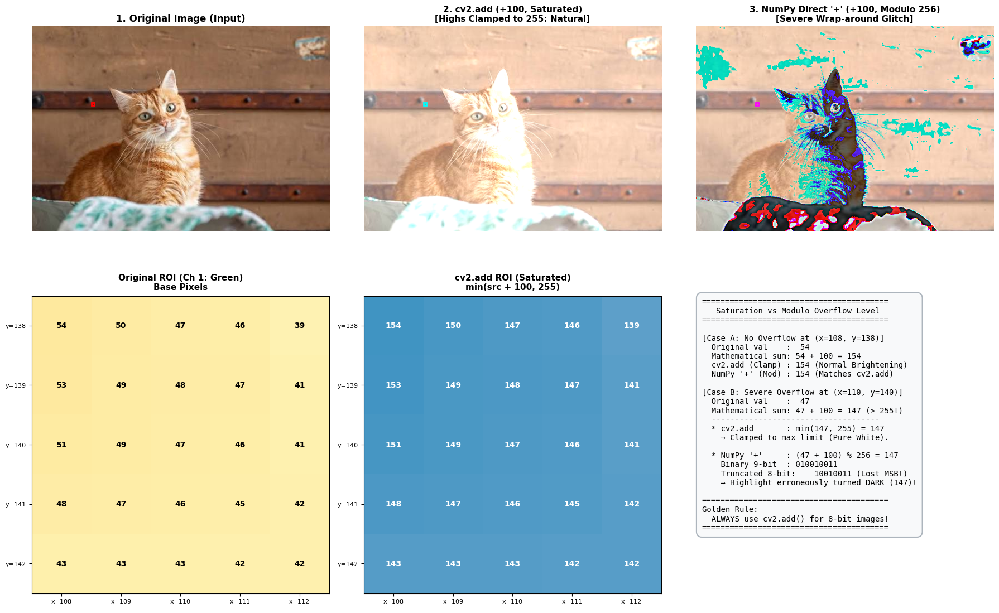

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

# ==============================================================================
# 0. 影像防呆載入機制（若無 images.jpg 則自動合成）
# ==============================================================================
img_path = 'images.jpg'
if not os.path.exists(img_path):
    print("⚠️ [images.jpg] not found. Synthesizing a demo image...")
    syn_img = np.zeros((300, 300, 3), dtype=np.uint8)
    syn_img[:] = (80, 50, 30)  # 木箱深褐色背景
    cv2.ellipse(syn_img, (150, 160), (100, 80), 0, 0, 360, (30, 140, 255), -1)  # 橘貓臉
    cv2.circle(syn_img, (110, 140), 18, (0, 220, 220), -1)  # 貓眼 (黃綠)
    cv2.circle(syn_img, (190, 140), 18, (0, 220, 220), -1)
    cv2.circle(syn_img, (110, 140), 7, (20, 20, 20), -1)    # 瞳孔 (黑)
    cv2.circle(syn_img, (190, 140), 7, (20, 20, 20), -1)
    cv2.imwrite(img_path, syn_img)

src = cv2.imread(img_path)

# ==============================================================================
# 1. 執行加法運算：飽和加法 vs 模數溢位加法
# ==============================================================================
# 建立一個全域增亮純量或圖層 (加亮 100)
bright_val = 100
bias_img = np.full_like(src, bright_val)

# 正確做法：OpenCV 飽和加法 (上限 255)
add_saturated = cv2.add(src, bias_img)

# 常見致命錯誤：NumPy 模數加法 (溢位回繞)
add_modulo = src + bias_img

# ==============================================================================
# 2. 定義 5x5 ROI 觀察區域（選在貓臉亮部與邊界處，原值接近 180~220）
# ==============================================================================
# 貓眼周邊高亮區域 (加上 100 後必然超過 255)
roi_y, roi_x = 138, 108
roi_h, roi_w = 5, 5

# 取 Channel 1 (G 通道，在貓臉與貓眼中具有豐富動態範圍) 分析
roi_src = src[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 1]
roi_sat = add_saturated[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 1]
roi_mod = add_modulo[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 1]

# ==============================================================================
# 3. 繪圖輔助函式：繪製 5x5 像素數值矩陣
# ==============================================================================
def draw_pixel_matrix(ax, matrix, title, cmap='Blues'):
    im = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=255)
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8)

    for r in range(matrix.shape[0]):
        for c in range(matrix.shape[1]):
            val = int(matrix[r, c])
            text_color = "white" if val > 130 else "black"
            ax.text(c, r, f"{val}", ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

    ax.set_xticks(range(matrix.shape[1]))
    ax.set_yticks(range(matrix.shape[0]))
    ax.set_xticklabels([f"x={roi_x + c}" for c in range(matrix.shape[1])], fontsize=8)
    ax.set_yticklabels([f"y={roi_y + r}" for r in range(matrix.shape[0])], fontsize=8)
    return im

# ==============================================================================
# 4. Matplotlib 綜合畫布（英文標題）
# ==============================================================================
fig = plt.figure(figsize=(18, 12))

# --- 第一層：宏觀影像展示 ---
ax1 = plt.subplot2grid((2, 3), (0, 0))
ax1.imshow(cv2.cvtColor(src, cv2.COLOR_BGR2RGB))
rect1 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='red', facecolor='none')
ax1.add_patch(rect1)
ax1.set_title("1. Original Image (Input)", fontsize=12, fontweight='bold')
ax1.axis('off')

ax2 = plt.subplot2grid((2, 3), (0, 1))
ax2.imshow(cv2.cvtColor(add_saturated, cv2.COLOR_BGR2RGB))
rect2 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='cyan', facecolor='none')
ax2.add_patch(rect2)
ax2.set_title("2. cv2.add (+100, Saturated)\n[Highs Clamped to 255: Natural]", fontsize=11, fontweight='bold')
ax2.axis('off')

ax3 = plt.subplot2grid((2, 3), (0, 2))
ax3.imshow(cv2.cvtColor(add_modulo, cv2.COLOR_BGR2RGB))
rect3 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='magenta', facecolor='none')
ax3.add_patch(rect3)
ax3.set_title("3. NumPy Direct '+' (+100, Modulo 256)\n[Severe Wrap-around Glitch]", fontsize=11, fontweight='bold')
ax3.axis('off')

# --- 第二層：微觀 5x5 ROI 數值熱力圖 ---
ax4 = plt.subplot2grid((2, 3), (1, 0))
draw_pixel_matrix(ax4, roi_src, "Original ROI (Ch 1: Green)\nBase Pixels", cmap='YlOrBr')

ax5 = plt.subplot2grid((2, 3), (1, 1))
draw_pixel_matrix(ax5, roi_sat, "cv2.add ROI (Saturated)\nmin(src + 100, 255)", cmap='PuBu')

# --- 第三層：底層二進位溢位運算拆解看板 ---
ax6 = plt.subplot2grid((2, 3), (1, 2))
ax6.axis('off')

# 取樣兩個代表點：未超標點 vs 超標溢位點
# 點 A (未超標暗部): (row 0, col 0)
v_A_src = int(roi_src[0, 0])
v_A_sat = int(roi_sat[0, 0])
v_A_mod = int(roi_mod[0, 0])

# 點 B (超標高亮部): (row 2, col 2 中心點)
v_B_src = int(roi_src[2, 2])
v_B_sat = int(roi_sat[2, 2])
v_B_mod = int(roi_mod[2, 2])

analysis_text = (
    "========================================\n"
    "   Saturation vs Modulo Overflow Level   \n"
    "========================================\n\n"
    f"[Case A: No Overflow at (x={roi_x}, y={roi_y})]\n"
    f"  Original val    : {v_A_src:>3d}\n"
    f"  Mathematical sum: {v_A_src} + {bright_val} = {v_A_src + bright_val}\n"
    f"  cv2.add (Clamp) : {v_A_sat:>3d} (Normal Brightening)\n"
    f"  NumPy '+' (Mod) : {v_A_mod:>3d} (Matches cv2.add)\n\n"
    f"[Case B: Severe Overflow at (x={roi_x+2}, y={roi_y+2})]\n"
    f"  Original val    : {v_B_src:>3d}\n"
    f"  Mathematical sum: {v_B_src} + {bright_val} = {v_B_src + bright_val} (> 255!)\n"
    "  ------------------------------------\n"
    f"  * cv2.add       : min({v_B_src + bright_val}, 255) = {v_B_sat:>3d}\n"
    "    → Clamped to max limit (Pure White).\n\n"
    f"  * NumPy '+'     : ({v_B_src} + {bright_val}) % 256 = {v_B_mod:>3d}\n"
    f"    Binary 9-bit  : {v_B_src + bright_val:09b}\n"
    f"    Truncated 8-bit:    {v_B_mod:08b} (Lost MSB!)\n"
    f"    → Highlight erroneously turned DARK ({v_B_mod})!\n\n"
    "========================================\n"
    "Golden Rule:\n"
    "  ALWAYS use cv2.add() for 8-bit images!\n"
    "========================================"
)

ax6.text(0.02, 0.95, analysis_text, transform=ax6.transAxes,
         fontsize=10, family='monospace', verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.7', facecolor='#f8f9fa', edgecolor='#adb5bd', linewidth=1.5))

plt.tight_layout()
plt.show()


### ➖ 影像減法（cv2.subtract）：光照去除與負值歸零

- 應用場景
- 🎯 背景消除
- 🔍 運動檢測
- 📊 差異分析

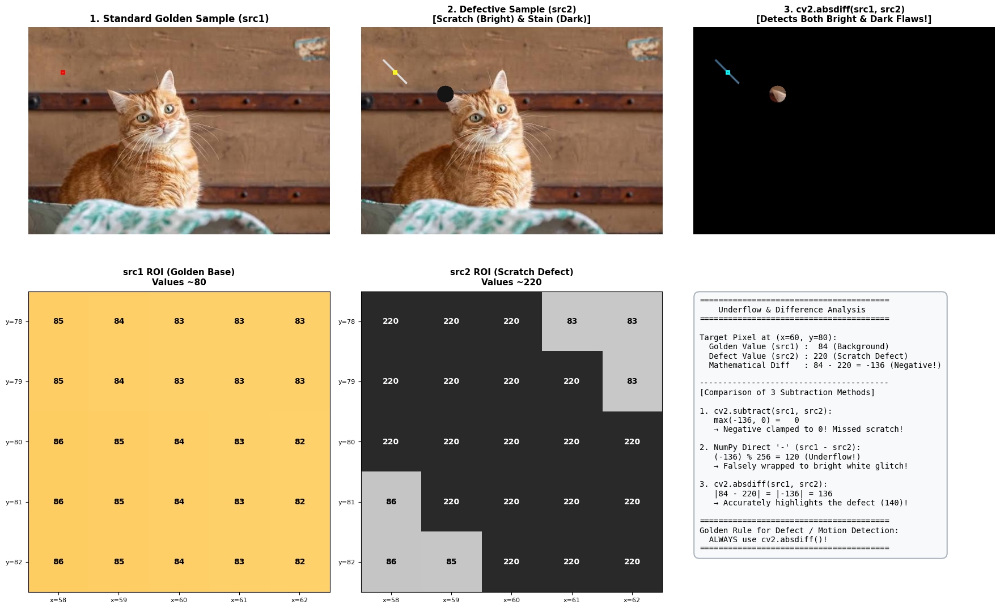

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

# ==============================================================================
# 0. 影像防呆載入機制（若無 images.jpg 則自動合成）
# ==============================================================================
img_path = 'images.jpg'
if not os.path.exists(img_path):
    print("⚠️ [images.jpg] not found. Synthesizing a demo image...")
    syn_img = np.zeros((300, 300, 3), dtype=np.uint8)
    syn_img[:] = (80, 50, 30)  # 木箱深褐色背景
    cv2.ellipse(syn_img, (150, 160), (100, 80), 0, 0, 360, (30, 140, 255), -1)  # 橘貓臉
    cv2.circle(syn_img, (110, 140), 18, (0, 220, 220), -1)  # 貓眼 (黃綠)
    cv2.circle(syn_img, (190, 140), 18, (0, 220, 220), -1)
    cv2.circle(syn_img, (110, 140), 7, (20, 20, 20), -1)    # 瞳孔 (黑)
    cv2.circle(syn_img, (190, 140), 7, (20, 20, 20), -1)
    cv2.imwrite(img_path, syn_img)

src1 = cv2.imread(img_path)

# ==============================================================================
# 1. 建立具有微小差異的瑕疵對比圖 (src2: 模擬灰塵/刮痕與光照變暗)
# ==============================================================================
src2 = src1.copy()
# 模擬在木箱上出現白色刮痕 (比原圖亮: 刮痕處 src2 > src1)
cv2.line(src2, (40, 60), (80, 100), (220, 220, 220), 3)
# 模擬在貓臉額頭出現深色油墨污漬 (比原圖暗: 污漬處 src2 < src1)
cv2.circle(src2, (150, 120), 15, (20, 20, 20), -1)

# 執行三種減法
sub_saturated = cv2.subtract(src1, src2)   # src1 - src2 (負數截斷為 0)
sub_modulo    = src1 - src2                # 致命錯誤: uint8 下溢位回繞
abs_diff      = cv2.absdiff(src1, src2)    # 正確全能差分: |src1 - src2|

# ==============================================================================
# 2. 定義 5x5 ROI 觀察區域（選在白色刮痕邊界處）
# ==============================================================================
# 在刮痕位置：原圖背景深褐 (B約80)，刮痕亮白 (B約220)
# 因此 src1 - src2 = 80 - 220 = -140 (必然觸發負數截斷與下溢位)
roi_y, roi_x = 78, 58
roi_h, roi_w = 5, 5

# 取 Channel 0 (B 通道) 分析
roi_src1 = src1[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
roi_src2 = src2[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
roi_sub  = sub_saturated[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
roi_abs  = abs_diff[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]

# ==============================================================================
# 3. 繪圖輔助函式：繪製 5x5 像素數值矩陣
# ==============================================================================
def draw_pixel_matrix(ax, matrix, title, cmap='Blues'):
    im = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=255)
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8)

    for r in range(matrix.shape[0]):
        for c in range(matrix.shape[1]):
            val = int(matrix[r, c])
            text_color = "white" if val > 130 else "black"
            ax.text(c, r, f"{val}", ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

    ax.set_xticks(range(matrix.shape[1]))
    ax.set_yticks(range(matrix.shape[0]))
    ax.set_xticklabels([f"x={roi_x + c}" for c in range(matrix.shape[1])], fontsize=8)
    ax.set_yticklabels([f"y={roi_y + r}" for r in range(matrix.shape[0])], fontsize=8)
    return im

# ==============================================================================
# 4. Matplotlib 綜合畫布（英文標題）
# ==============================================================================
fig = plt.figure(figsize=(18, 12))

# --- 第一層：宏觀影像展示 ---
ax1 = plt.subplot2grid((2, 3), (0, 0))
ax1.imshow(cv2.cvtColor(src1, cv2.COLOR_BGR2RGB))
rect1 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='red', facecolor='none')
ax1.add_patch(rect1)
ax1.set_title("1. Standard Golden Sample (src1)", fontsize=12, fontweight='bold')
ax1.axis('off')

ax2 = plt.subplot2grid((2, 3), (0, 1))
ax2.imshow(cv2.cvtColor(src2, cv2.COLOR_BGR2RGB))
rect2 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='yellow', facecolor='none')
ax2.add_patch(rect2)
ax2.set_title("2. Defective Sample (src2)\n[Scratch (Bright) & Stain (Dark)]", fontsize=11, fontweight='bold')
ax2.axis('off')

ax3 = plt.subplot2grid((2, 3), (0, 2))
ax3.imshow(cv2.cvtColor(abs_diff, cv2.COLOR_BGR2RGB))
rect3 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='cyan', facecolor='none')
ax3.add_patch(rect3)
ax3.set_title("3. cv2.absdiff(src1, src2)\n[Detects Both Bright & Dark Flaws!]", fontsize=11, fontweight='bold')
ax3.axis('off')

# --- 第二層：微觀 5x5 ROI 數值熱力圖 ---
ax4 = plt.subplot2grid((2, 3), (1, 0))
draw_pixel_matrix(ax4, roi_src1, "src1 ROI (Golden Base)\nValues ~80", cmap='YlOrBr')

ax5 = plt.subplot2grid((2, 3), (1, 1))
draw_pixel_matrix(ax5, roi_src2, "src2 ROI (Scratch Defect)\nValues ~220", cmap='Greys')

# --- 第三層：底層下溢位與差分運算拆解看板 ---
ax6 = plt.subplot2grid((2, 3), (1, 2))
ax6.axis('off')

# 取樣中心點 (刮痕正中心) 進行數值拆解
v1 = int(roi_src1[2, 2])
v2 = int(roi_src2[2, 2])
v_sub = int(roi_sub[2, 2])
v_mod = int((v1 - v2) % 256)
v_abs = int(roi_abs[2, 2])

analysis_text = (
    "========================================\n"
    "    Underflow & Difference Analysis     \n"
    "========================================\n\n"
    f"Target Pixel at (x={roi_x+2}, y={roi_y+2}):\n"
    f"  Golden Value (src1) : {v1:>3d} (Background)\n"
    f"  Defect Value (src2) : {v2:>3d} (Scratch Defect)\n"
    f"  Mathematical Diff   : {v1} - {v2} = {v1 - v2} (Negative!)\n\n"
    "----------------------------------------\n"
    "[Comparison of 3 Subtraction Methods]\n\n"
    f"1. cv2.subtract(src1, src2):\n"
    f"   max({v1 - v2}, 0) = {v_sub:>3d}\n"
    "   → Negative clamped to 0! Missed scratch!\n\n"
    f"2. NumPy Direct '-' (src1 - src2):\n"
    f"   ({v1 - v2}) % 256 = {v_mod:>3d} (Underflow!)\n"
    "   → Falsely wrapped to bright white glitch!\n\n"
    f"3. cv2.absdiff(src1, src2):\n"
    f"   |{v1} - {v2}| = |{v1 - v2}| = {v_abs:>3d}\n"
    "   → Accurately highlights the defect (140)!\n\n"
    "========================================\n"
    "Golden Rule for Defect / Motion Detection:\n"
    "  ALWAYS use cv2.absdiff()!\n"
    "========================================"
)

ax6.text(0.02, 0.95, analysis_text, transform=ax6.transAxes,
         fontsize=10, family='monospace', verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.7', facecolor='#f8f9fa', edgecolor='#adb5bd', linewidth=1.5))

plt.tight_layout()
plt.show()


### ✖️ 影像乘法（cv2.multiply）：動態對比縮放與暗角

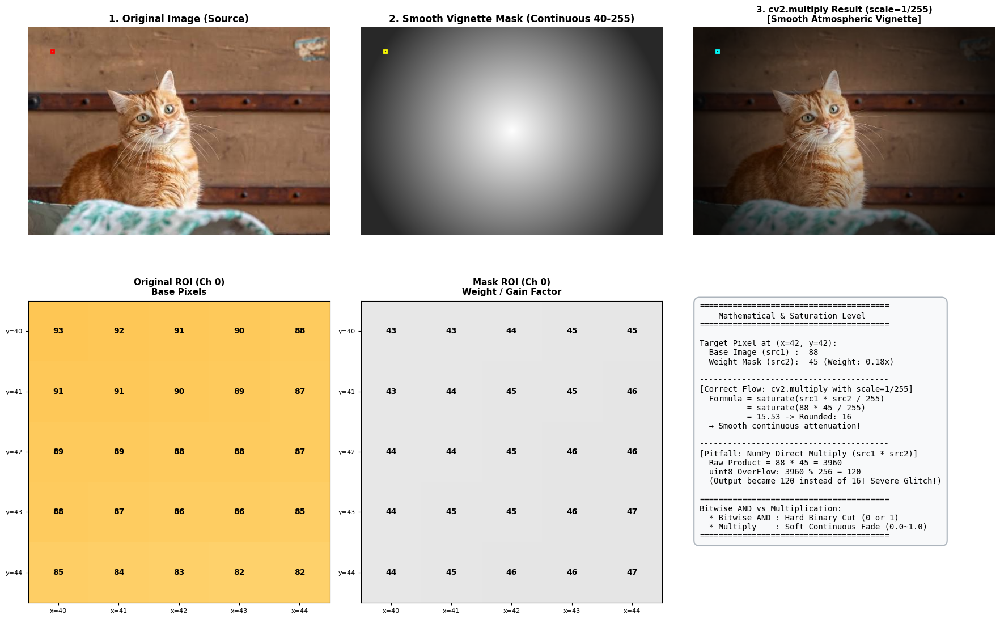

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

# ==============================================================================
# 0. 影像防呆載入機制（若無 images.jpg 則自動合成）
# ==============================================================================
img_path = 'images.jpg'
if not os.path.exists(img_path):
    print("⚠️ [images.jpg] not found. Synthesizing a demo image...")
    syn_img = np.zeros((300, 300, 3), dtype=np.uint8)
    syn_img[:] = (80, 50, 30)  # 木箱深褐色背景
    cv2.ellipse(syn_img, (150, 160), (100, 80), 0, 0, 360, (30, 140, 255), -1)  # 橘貓臉
    cv2.circle(syn_img, (110, 140), 18, (0, 220, 220), -1)  # 貓眼 (黃綠)
    cv2.circle(syn_img, (190, 140), 18, (0, 220, 220), -1)
    cv2.circle(syn_img, (110, 140), 7, (20, 20, 20), -1)    # 瞳孔 (黑)
    cv2.circle(syn_img, (190, 140), 7, (20, 20, 20), -1)
    cv2.imwrite(img_path, syn_img)

src1 = cv2.imread(img_path)
H, W, C = src1.shape

# ==============================================================================
# 1. 建立具有連續平滑過渡（羽化/漸層）的亮暗乘法遮罩 (src2)
# ==============================================================================
# 建立一個徑向漸層暗角遮罩 (Vignette Mask): 中心為 255，邊緣漸變為 40
Y, X = np.ogrid[:H, :W]
center_y, center_x = H // 2, W // 2
dist_from_center = np.sqrt((X - center_x)**2 + (Y - center_y)**2)
max_dist = np.sqrt(center_x**2 + center_y**2)

# 正規化至 0.0 ~ 1.0，並轉為 40 ~ 255 的 uint8 漸層
mask_normalized = 1.0 - (dist_from_center / max_dist)
mask_gradient = np.clip(mask_normalized * 255, 40, 255).astype(np.uint8)
src2 = cv2.cvtColor(mask_gradient, cv2.COLOR_GRAY2BGR)

# ==============================================================================
# 2. 執行乘法運算（對比正確的 scale=1.0/255 與常見錯誤的純相乘）
# ==============================================================================
# 正確做法：加上 scale=1.0/255.0
mult_correct = cv2.multiply(src1, src2, scale=1.0 / 255.0)

# 常見致命錯誤（NumPy 直接乘）：發生 uint8 overflow 溢位
mult_overflow = src1 * src2  # 會觸發 modulo 256 回繞

# ==============================================================================
# 3. 定義 5x5 ROI 觀察區域（選在暗角過渡漸層區）
# ==============================================================================
roi_y, roi_x = 40, 40
roi_h, roi_w = 5, 5

# 取 Channel 0 (B 通道) 分析
roi_src1    = src1[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
roi_src2    = src2[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
roi_correct = mult_correct[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]

# ==============================================================================
# 4. 繪圖輔助函式：繪製 5x5 像素數值矩陣
# ==============================================================================
def draw_pixel_matrix(ax, matrix, title, cmap='Blues'):
    im = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=255)
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8)

    for r in range(matrix.shape[0]):
        for c in range(matrix.shape[1]):
            val = int(matrix[r, c])
            text_color = "white" if val > 130 else "black"
            ax.text(c, r, f"{val}", ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

    ax.set_xticks(range(matrix.shape[1]))
    ax.set_yticks(range(matrix.shape[0]))
    ax.set_xticklabels([f"x={roi_x + c}" for c in range(matrix.shape[1])], fontsize=8)
    ax.set_yticklabels([f"y={roi_y + r}" for r in range(matrix.shape[0])], fontsize=8)
    return im

# ==============================================================================
# 5. Matplotlib 綜合畫布（英文標題）
# ==============================================================================
fig = plt.figure(figsize=(18, 12))

# --- 第一層：宏觀影像比較 ---
ax1 = plt.subplot2grid((2, 3), (0, 0))
ax1.imshow(cv2.cvtColor(src1, cv2.COLOR_BGR2RGB))
rect1 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='red', facecolor='none')
ax1.add_patch(rect1)
ax1.set_title("1. Original Image (Source)", fontsize=12, fontweight='bold')
ax1.axis('off')

ax2 = plt.subplot2grid((2, 3), (0, 1))
ax2.imshow(cv2.cvtColor(src2, cv2.COLOR_BGR2RGB))
rect2 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='yellow', facecolor='none')
ax2.add_patch(rect2)
ax2.set_title("2. Smooth Vignette Mask (Continuous 40-255)", fontsize=12, fontweight='bold')
ax2.axis('off')

ax3 = plt.subplot2grid((2, 3), (0, 2))
ax3.imshow(cv2.cvtColor(mult_correct, cv2.COLOR_BGR2RGB))
rect3 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='cyan', facecolor='none')
ax3.add_patch(rect3)
ax3.set_title("3. cv2.multiply Result (scale=1/255)\n[Smooth Atmospheric Vignette]", fontsize=11, fontweight='bold')
ax3.axis('off')

# --- 第二層：中間 5x5 ROI 數值微觀圖解 ---
ax4 = plt.subplot2grid((2, 3), (1, 0))
draw_pixel_matrix(ax4, roi_src1, "Original ROI (Ch 0)\nBase Pixels", cmap='YlOrBr')

ax5 = plt.subplot2grid((2, 3), (1, 1))
draw_pixel_matrix(ax5, roi_src2, "Mask ROI (Ch 0)\nWeight / Gain Factor", cmap='Greys')

# --- 第三層：底層縮放計算與溢位防坑拆解看板 ---
ax6 = plt.subplot2grid((2, 3), (1, 2))
ax6.axis('off')

# 取中心像素驗算
p_src = int(roi_src1[2, 2])
p_mask = int(roi_src2[2, 2])
p_out = int(roi_correct[2, 2])
p_overflow = int(mult_overflow[roi_y+2, roi_x+2, 0])

calc_float = (p_src * p_mask) / 255.0

analysis_text = (
    "========================================\n"
    "    Mathematical & Saturation Level     \n"
    "========================================\n\n"
    f"Target Pixel at (x={roi_x+2}, y={roi_y+2}):\n"
    f"  Base Image (src1) : {p_src:>3d}\n"
    f"  Weight Mask (src2): {p_mask:>3d} (Weight: {p_mask/255.0:.2f}x)\n\n"
    "----------------------------------------\n"
    "[Correct Flow: cv2.multiply with scale=1/255]\n"
    f"  Formula = saturate(src1 * src2 / 255)\n"
    f"          = saturate({p_src} * {p_mask} / 255)\n"
    f"          = {calc_float:.2f} -> Rounded: {p_out}\n"
    "  → Smooth continuous attenuation!\n\n"
    "----------------------------------------\n"
    "[Pitfall: NumPy Direct Multiply (src1 * src2)]\n"
    f"  Raw Product = {p_src} * {p_mask} = {p_src * p_mask}\n"
    f"  uint8 OverFlow: {p_src * p_mask} % 256 = {p_overflow}\n"
    f"  (Output became {p_overflow} instead of {p_out}! Severe Glitch!)\n\n"
    "========================================\n"
    "Bitwise AND vs Multiplication:\n"
    "  * Bitwise AND : Hard Binary Cut (0 or 1)\n"
    "  * Multiply    : Soft Continuous Fade (0.0~1.0)\n"
    "========================================"
)

ax6.text(0.02, 0.95, analysis_text, transform=ax6.transAxes,
         fontsize=10, family='monospace', verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.7', facecolor='#f8f9fa', edgecolor='#adb5bd', linewidth=1.5))

plt.tight_layout()
plt.show()


### ➗ 影像除法（cv2.divide）：平場校正與陰影消除

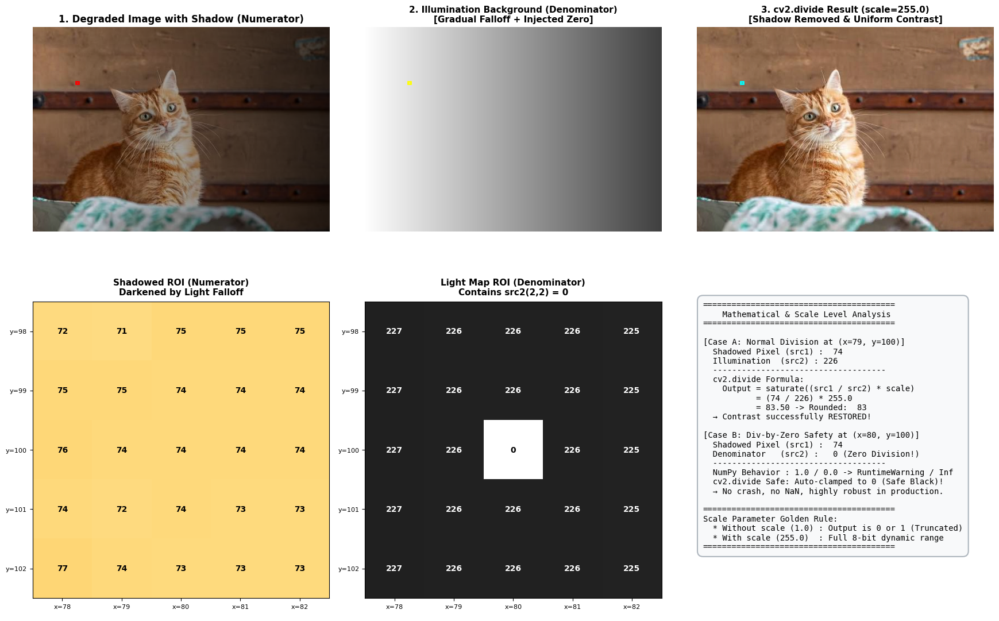

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

# ==============================================================================
# 0. 影像防呆載入機制（若無 images.jpg 則自動合成）
# ==============================================================================
img_path = 'images.jpg'
if not os.path.exists(img_path):
    print("⚠️ [images.jpg] not found. Synthesizing a demo image...")
    syn_img = np.zeros((300, 300, 3), dtype=np.uint8)
    syn_img[:] = (80, 50, 30)  # 木箱深褐色背景
    cv2.ellipse(syn_img, (150, 160), (100, 80), 0, 0, 360, (30, 140, 255), -1)  # 橘貓臉
    cv2.circle(syn_img, (110, 140), 18, (0, 220, 220), -1)  # 貓眼 (黃綠)
    cv2.circle(syn_img, (190, 140), 18, (0, 220, 220), -1)
    cv2.circle(syn_img, (110, 140), 7, (20, 20, 20), -1)    # 瞳孔 (黑)
    cv2.circle(syn_img, (190, 140), 7, (20, 20, 20), -1)
    cv2.imwrite(img_path, syn_img)

src1 = cv2.imread(img_path)
H, W, C = src1.shape

# ==============================================================================
# 1. 模擬不均勻陰影光照 (Illumination Mask, src2)
# ==============================================================================
# 建立從左到右逐漸變暗的光照漸層（模擬左側打光、右側重度陰影遮蔽）
gradient_x = np.linspace(1.0, 0.25, W, dtype=np.float32)
illumination_map = np.tile(gradient_x, (H, 1))

# 讓原圖乘以陰影，得到受光照劣化、右側一片死黑的影像 (shadowed_img)
shadowed_img = np.clip(src1.astype(np.float32) * illumination_map[:, :, np.newaxis], 0, 255).astype(np.uint8)

# 估算背景低頻光照（實務上可利用大半徑高斯模糊估算環境光，或工廠拍一張白色純板）
# 這裡轉為 uint8 光照估算圖 (src2)
src2 = np.clip(illumination_map * 255.0, 0, 255).astype(np.uint8)
src2 = cv2.cvtColor(src2, cv2.COLOR_GRAY2BGR)

# 人工埋設一個極端點：分母為 0 的測試像素，展示 OpenCV 零除安全機制
src2[100, 80, :] = 0

# ==============================================================================
# 2. 執行除法校正：cv2.divide (scale=255.0)
# ==============================================================================
# 正確做法：加上 scale=255.0
div_corrected = cv2.divide(shadowed_img, src2, scale=255.0)

# ==============================================================================
# 3. 定義 5x5 ROI 觀察區域（選在包含分母為 0 的極端測試點周圍）
# ==============================================================================
roi_y, roi_x = 98, 78
roi_h, roi_w = 5, 5

# 取 Channel 0 (B 通道) 分析
roi_shadow = shadowed_img[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
roi_light  = src2[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
roi_div    = div_corrected[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]

# ==============================================================================
# 4. 繪圖輔助函式：繪製 5x5 像素數值矩陣
# ==============================================================================
def draw_pixel_matrix(ax, matrix, title, cmap='Blues'):
    im = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=255)
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8)

    for r in range(matrix.shape[0]):
        for c in range(matrix.shape[1]):
            val = int(matrix[r, c])
            text_color = "white" if val > 130 else "black"
            ax.text(c, r, f"{val}", ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

    ax.set_xticks(range(matrix.shape[1]))
    ax.set_yticks(range(matrix.shape[0]))
    ax.set_xticklabels([f"x={roi_x + c}" for c in range(matrix.shape[1])], fontsize=8)
    ax.set_yticklabels([f"y={roi_y + r}" for r in range(matrix.shape[0])], fontsize=8)
    return im

# ==============================================================================
# 5. Matplotlib 綜合畫布（英文標題）
# ==============================================================================
fig = plt.figure(figsize=(18, 12))

# --- 第一層：宏觀影像展示 ---
ax1 = plt.subplot2grid((2, 3), (0, 0))
ax1.imshow(cv2.cvtColor(shadowed_img, cv2.COLOR_BGR2RGB))
rect1 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='red', facecolor='none')
ax1.add_patch(rect1)
ax1.set_title("1. Degraded Image with Shadow (Numerator)", fontsize=12, fontweight='bold')
ax1.axis('off')

ax2 = plt.subplot2grid((2, 3), (0, 1))
ax2.imshow(cv2.cvtColor(src2, cv2.COLOR_BGR2RGB))
rect2 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='yellow', facecolor='none')
ax2.add_patch(rect2)
ax2.set_title("2. Illumination Background (Denominator)\n[Gradual Falloff + Injected Zero]", fontsize=11, fontweight='bold')
ax2.axis('off')

ax3 = plt.subplot2grid((2, 3), (0, 2))
ax3.imshow(cv2.cvtColor(div_corrected, cv2.COLOR_BGR2RGB))
rect3 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='cyan', facecolor='none')
ax3.add_patch(rect3)
ax3.set_title("3. cv2.divide Result (scale=255.0)\n[Shadow Removed & Uniform Contrast]", fontsize=11, fontweight='bold')
ax3.axis('off')

# --- 第二層：微觀 5x5 ROI 數值熱力圖 ---
ax4 = plt.subplot2grid((2, 3), (1, 0))
draw_pixel_matrix(ax4, roi_shadow, "Shadowed ROI (Numerator)\nDarkened by Light Falloff", cmap='YlOrBr')

ax5 = plt.subplot2grid((2, 3), (1, 1))
draw_pixel_matrix(ax5, roi_light, "Light Map ROI (Denominator)\nContains src2(2,2) = 0", cmap='Greys')

# --- 第三層：底層零除防護與浮點縮放拆解看板 ---
ax6 = plt.subplot2grid((2, 3), (1, 2))
ax6.axis('off')

# 取樣兩個點：一般正常校正點 vs 分母為 0 的極端點
# 點 A (正常點): (row 2, col 1: x=79, y=100)
num_A = int(roi_shadow[2, 1])
den_A = int(roi_light[2, 1])
out_A = int(roi_div[2, 1])
calc_A = (num_A / den_A) * 255.0 if den_A != 0 else 0

# 點 B (零除點): (row 2, col 2: x=80, y=100)
num_B = int(roi_shadow[2, 2])
den_B = int(roi_light[2, 2])
out_B = int(roi_div[2, 2])

analysis_text = (
    "========================================\n"
    "    Mathematical & Scale Level Analysis \n"
    "========================================\n\n"
    f"[Case A: Normal Division at (x={roi_x+1}, y={roi_y+2})]\n"
    f"  Shadowed Pixel (src1) : {num_A:>3d}\n"
    f"  Illumination  (src2) : {den_A:>3d}\n"
    "  ------------------------------------\n"
    "  cv2.divide Formula:\n"
    f"    Output = saturate((src1 / src2) * scale)\n"
    f"           = ({num_A} / {den_A}) * 255.0\n"
    f"           = {calc_A:.2f} -> Rounded: {out_A:>3d}\n"
    "  → Contrast successfully RESTORED!\n\n"
    f"[Case B: Div-by-Zero Safety at (x={roi_x+2}, y={roi_y+2})]\n"
    f"  Shadowed Pixel (src1) : {num_B:>3d}\n"
    f"  Denominator   (src2) :   0 (Zero Division!)\n"
    "  ------------------------------------\n"
    "  NumPy Behavior : 1.0 / 0.0 -> RuntimeWarning / Inf\n"
    f"  cv2.divide Safe: Auto-clamped to {out_B} (Safe Black)!\n"
    "  → No crash, no NaN, highly robust in production.\n\n"
    "========================================\n"
    "Scale Parameter Golden Rule:\n"
    "  * Without scale (1.0) : Output is 0 or 1 (Truncated)\n"
    "  * With scale (255.0)  : Full 8-bit dynamic range\n"
    "========================================"
)

ax6.text(0.02, 0.95, analysis_text, transform=ax6.transAxes,
         fontsize=10, family='monospace', verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.7', facecolor='#f8f9fa', edgecolor='#adb5bd', linewidth=1.5))

plt.tight_layout()
plt.show()


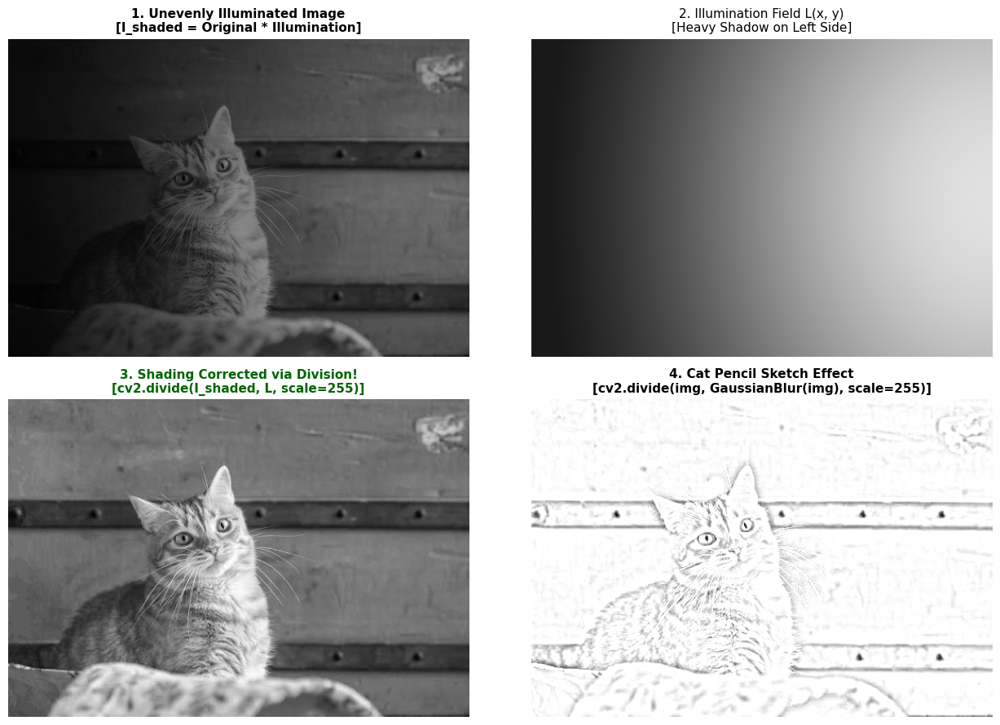

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀取橘貓灰階影像
img = cv2.imread("images.jpg", cv2.IMREAD_GRAYSCALE)
H, W = img.shape

# =========================================================================
# 應用 A：光照不均校正 / 陰影消除 (Illumination / Shading Correction)
# =========================================================================
# 模擬一張「左暗右亮 + 四周嚴重暗角」的不均勻照明光場 L(x, y) (範圍 30 ~ 255)
y, x = np.mgrid[0:H, 0:W]
illumination_field = (255 * (0.15 + 0.85 * (x / W)) * np.exp(-((x - W*0.7)**2 + (y - H*0.5)**2) / (2 * (W*0.6)**2)))
illumination_u8 = np.clip(illumination_field, 25, 255).astype(np.uint8)

# 產生受陰影污染的橘貓圖：I_shaded = I_orig * (L / 255)
shaded_cat = cv2.multiply(img, illumination_u8, scale=1.0/255.0)

# 【核心神技】利用 cv2.divide 將受損圖除以估計出的照明場 (務必加上 scale=255.0！)
# 實務上若不知道真實光場，可用超大核高斯模糊 cv2.GaussianBlur(shaded_cat, (0,0), sigmaX=60) 來估計背景光場
restored_cat = cv2.divide(shaded_cat, illumination_u8, scale=255.0)

# =========================================================================
# 應用 B：影像除法製作「鉛筆素描特效 (Pencil Sketch via Division)」
# =========================================================================
# 1. 對橘貓做高斯模糊
blurred_cat = cv2.GaussianBlur(img, (25, 25), 0)
# 2. 原圖除以模糊圖 (scale=255)：平坦區變 255 純白紙張，邊緣凹陷處留下深色鉛筆線條！
pencil_sketch = cv2.divide(img, blurred_cat, scale=255.0)

# =========================================================================
# 視覺化展示 (2x2 網格，全英文標題)
# =========================================================================
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.ravel()

axes[0].imshow(shaded_cat, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("1. Unevenly Illuminated Image\n[I_shaded = Original * Illumination]", fontsize=11, fontweight='bold')

axes[1].imshow(illumination_u8, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("2. Illumination Field L(x, y)\n[Heavy Shadow on Left Side]", fontsize=11)

axes[2].imshow(restored_cat, cmap='gray', vmin=0, vmax=255)
axes[2].set_title("3. Shading Corrected via Division!\n[cv2.divide(I_shaded, L, scale=255)]", fontsize=11, fontweight='bold', color='darkgreen')

axes[3].imshow(pencil_sketch, cmap='gray', vmin=0, vmax=255)
axes[3].set_title("4. Cat Pencil Sketch Effect\n[cv2.divide(img, GaussianBlur(img), scale=255)]", fontsize=11, fontweight='bold')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()


## 1.2 絕對值差分（cv2.absdiff）：異物比對與瑕疵檢測

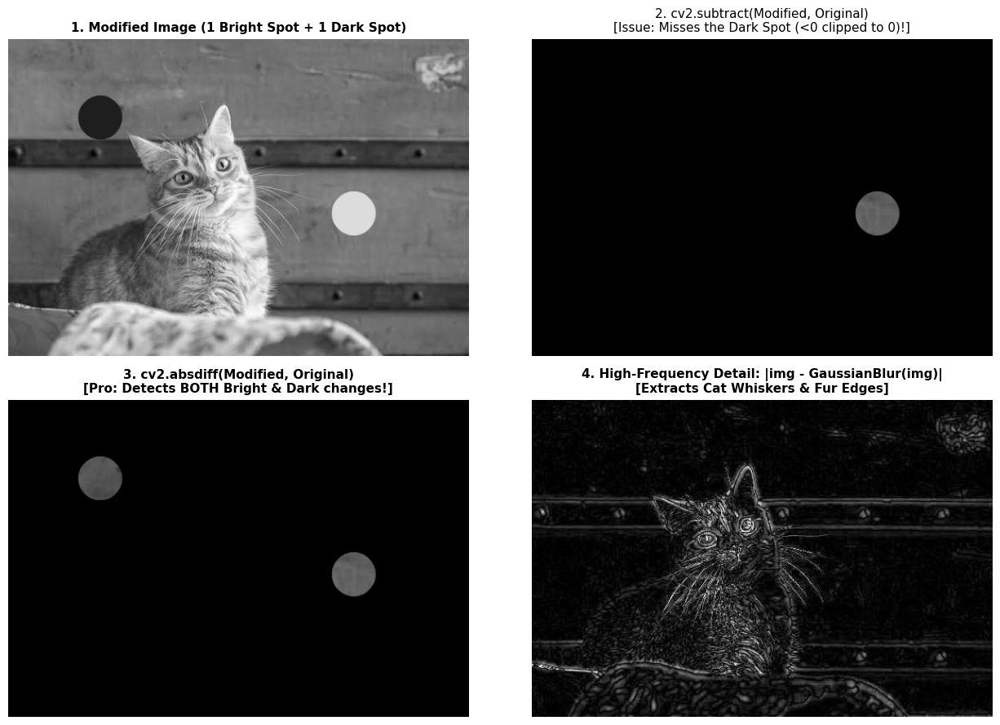

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀取橘貓彩色影像與灰階影像
img_bgr = cv2.imread("images.jpg")
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# -------------------------------------------------------------------------
# 應用 A：瑕疵 / 異物差分偵測 (Defect / Motion Detection)
# 複製一張圖，模擬畫面中多了一個小異物或亮斑
# -------------------------------------------------------------------------
img_modified = img_gray.copy()
H, W = img_gray.shape
cv2.circle(img_modified, (int(W*0.75), int(H*0.55)), 25, 220, -1, cv2.LINE_AA) # 模擬新增亮斑
cv2.circle(img_modified, (int(W*0.20), int(H*0.25)), 25, 30, -1, cv2.LINE_AA)  # 模擬新增暗斑

# 比較單向減法 cv2.subtract vs. 絕對值差分 cv2.absdiff
diff_one_way = cv2.subtract(img_modified, img_gray)  # 只抓得到「變亮」的亮斑，暗斑 (<0) 被截斷成 0 漏抓！
diff_abs     = cv2.absdiff(img_modified, img_gray)   # |A - B| 同時抓出「變亮」與「變暗」兩個異物！

# -------------------------------------------------------------------------
# 應用 B：原圖減去模糊圖 = 提取貓咪鬍鬚與邊緣高頻細節 (High-pass Detail)
# -------------------------------------------------------------------------
blurred = cv2.GaussianBlur(img_gray, (21, 21), 0)
whiskers_detail = cv2.absdiff(img_gray, blurred) * 3  # 放大 3 倍方便肉眼觀察細節

# 3. 視覺化展示 (2x2 網格)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.ravel()

axes[0].imshow(img_modified, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("1. Modified Image (1 Bright Spot + 1 Dark Spot)", fontsize=11, fontweight='bold')

axes[1].imshow(diff_one_way, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("2. cv2.subtract(Modified, Original)\n[Issue: Misses the Dark Spot (<0 clipped to 0)!]", fontsize=11)

axes[2].imshow(diff_abs, cmap='gray', vmin=0, vmax=255)
axes[2].set_title("3. cv2.absdiff(Modified, Original)\n[Pro: Detects BOTH Bright & Dark changes!]", fontsize=11, fontweight='bold')

axes[3].imshow(whiskers_detail, cmap='gray', vmin=0, vmax=255)
axes[3].set_title("4. High-Frequency Detail: |img - GaussianBlur(img)|\n[Extracts Cat Whiskers & Fur Edges]", fontsize=11, fontweight='bold')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()


## 1.3 影像線性加權與融合（cv2.addWeighted）：凸組合與透明度混合


- 加權混合公式
```
dst = α × img1 + β × img2 + γ
```

其中：
- α: 第一張影像的權重
- β: 第二張影像的權重
- γ: 標量值（通常為0）
- 通常 α + β = 1.0

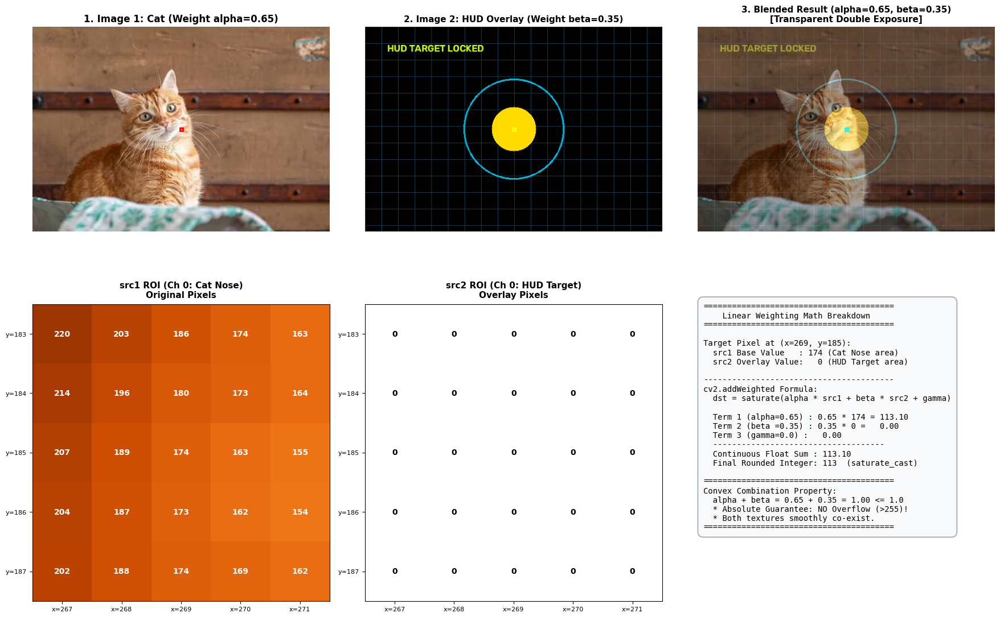

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

# ==============================================================================
# 0. 影像防呆載入機制（若無 images.jpg 則自動合成）
# ==============================================================================
img_path = 'images.jpg'
if not os.path.exists(img_path):
    print("⚠️ [images.jpg] not found. Synthesizing a demo image...")
    syn_img = np.zeros((300, 300, 3), dtype=np.uint8)
    syn_img[:] = (80, 50, 30)  # 木箱深褐色背景
    cv2.ellipse(syn_img, (150, 160), (100, 80), 0, 0, 360, (30, 140, 255), -1)  # 橘貓臉
    cv2.circle(syn_img, (110, 140), 18, (0, 220, 220), -1)  # 貓眼 (黃綠)
    cv2.circle(syn_img, (190, 140), 18, (0, 220, 220), -1)
    cv2.circle(syn_img, (110, 140), 7, (20, 20, 20), -1)    # 瞳孔 (黑)
    cv2.circle(syn_img, (190, 140), 7, (20, 20, 20), -1)
    cv2.imwrite(img_path, syn_img)

src1 = cv2.imread(img_path)
H, W, C = src1.shape

# ==============================================================================
# 1. 建立具有強烈幾何與對比的第二張圖 (src2: 科技幾何 HUD 網格)
# ==============================================================================
src2 = np.zeros_like(src1)
# 繪製青色網格與同心圓科技儀表 (HUD Overlay)
for r in range(0, H, 30):
    cv2.line(src2, (0, r), (W, r), (80, 60, 20), 1)
for c in range(0, W, 30):
    cv2.line(src2, (c, 0), (c, H), (80, 60, 20), 1)
cv2.circle(src2, (W // 2, H // 2), 90, (220, 180, 0), 2)   # 青黃色大環
cv2.circle(src2, (W // 2, H // 2), 40, (0, 220, 255), -1)  # 明亮黃色中心圓標
cv2.putText(src2, "HUD TARGET LOCKED", (40, 45), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 200), 2)

# ==============================================================================
# 2. 執行加權融合運算：cv2.addWeighted
# ==============================================================================
# 設定加權參數: 貓咪 65%, HUD 網格 35%, 亮度微調 gamma = 0
alpha = 0.65
beta = 0.35
gamma = 0.0

blended = cv2.addWeighted(src1, alpha, src2, beta, gamma)

# ==============================================================================
# 3. 定義 5x5 ROI 觀察區域（選在 HUD 明亮黃色中心標靶重疊區）
# ==============================================================================
roi_y, roi_x = H // 2 - 2, W // 2 - 2
roi_h, roi_w = 5, 5

# 取 Channel 0 (B 通道) 分析
roi_src1    = src1[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
roi_src2    = src2[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
roi_blended = blended[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]

# ==============================================================================
# 4. 繪圖輔助函式：繪製 5x5 像素數值矩陣
# ==============================================================================
def draw_pixel_matrix(ax, matrix, title, cmap='Blues'):
    im = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=255)
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8)

    for r in range(matrix.shape[0]):
        for c in range(matrix.shape[1]):
            val = int(matrix[r, c])
            text_color = "white" if val > 130 else "black"
            ax.text(c, r, f"{val}", ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

    ax.set_xticks(range(matrix.shape[1]))
    ax.set_yticks(range(matrix.shape[0]))
    ax.set_xticklabels([f"x={roi_x + c}" for c in range(matrix.shape[1])], fontsize=8)
    ax.set_yticklabels([f"y={roi_y + r}" for r in range(matrix.shape[0])], fontsize=8)
    return im

# ==============================================================================
# 5. Matplotlib 綜合畫布（英文標題）
# ==============================================================================
fig = plt.figure(figsize=(18, 12))

# --- 第一層：宏觀影像展示 ---
ax1 = plt.subplot2grid((2, 3), (0, 0))
ax1.imshow(cv2.cvtColor(src1, cv2.COLOR_BGR2RGB))
rect1 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='red', facecolor='none')
ax1.add_patch(rect1)
ax1.set_title(f"1. Image 1: Cat (Weight alpha={alpha})", fontsize=12, fontweight='bold')
ax1.axis('off')

ax2 = plt.subplot2grid((2, 3), (0, 1))
ax2.imshow(cv2.cvtColor(src2, cv2.COLOR_BGR2RGB))
rect2 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='yellow', facecolor='none')
ax2.add_patch(rect2)
ax2.set_title(f"2. Image 2: HUD Overlay (Weight beta={beta})", fontsize=11, fontweight='bold')
ax2.axis('off')

ax3 = plt.subplot2grid((2, 3), (0, 2))
ax3.imshow(cv2.cvtColor(blended, cv2.COLOR_BGR2RGB))
rect3 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='cyan', facecolor='none')
ax3.add_patch(rect3)
ax3.set_title(f"3. Blended Result (alpha={alpha}, beta={beta})\n[Transparent Double Exposure]", fontsize=11, fontweight='bold')
ax3.axis('off')

# --- 第二層：微觀 5x5 ROI 數值熱力圖 ---
ax4 = plt.subplot2grid((2, 3), (1, 0))
draw_pixel_matrix(ax4, roi_src1, "src1 ROI (Ch 0: Cat Nose)\nOriginal Pixels", cmap='YlOrBr')

ax5 = plt.subplot2grid((2, 3), (1, 1))
draw_pixel_matrix(ax5, roi_src2, "src2 ROI (Ch 0: HUD Target)\nOverlay Pixels", cmap='Greys')

# --- 第三層：底層線性加權數學看板 ---
ax6 = plt.subplot2grid((2, 3), (1, 2))
ax6.axis('off')

# 取中心像素進行精確算術拆解
p1 = int(roi_src1[2, 2])
p2 = int(roi_src2[2, 2])
p_out = int(roi_blended[2, 2])

term1 = alpha * p1
term2 = beta * p2
exact_sum = term1 + term2 + gamma

analysis_text = (
    "========================================\n"
    "    Linear Weighting Math Breakdown     \n"
    "========================================\n\n"
    f"Target Pixel at (x={roi_x+2}, y={roi_y+2}):\n"
    f"  src1 Base Value   : {p1:>3d} (Cat Nose area)\n"
    f"  src2 Overlay Value: {p2:>3d} (HUD Target area)\n\n"
    "----------------------------------------\n"
    "cv2.addWeighted Formula:\n"
    "  dst = saturate(alpha * src1 + beta * src2 + gamma)\n\n"
    f"  Term 1 (alpha={alpha:.2f}) : {alpha:.2f} * {p1} = {term1:>6.2f}\n"
    f"  Term 2 (beta ={beta:.2f}) : {beta:.2f} * {p2} = {term2:>6.2f}\n"
    f"  Term 3 (gamma={gamma:.1f}) : {gamma:>6.2f}\n"
    "  ------------------------------------\n"
    f"  Continuous Float Sum : {exact_sum:.2f}\n"
    f"  Final Rounded Integer: {p_out:>3d}  (saturate_cast)\n\n"
    "========================================\n"
    "Convex Combination Property:\n"
    f"  alpha + beta = {alpha:.2f} + {beta:.2f} = {alpha+beta:.2f} <= 1.0\n"
    "  * Absolute Guarantee: NO Overflow (>255)!\n"
    "  * Both textures smoothly co-exist.\n"
    "========================================"
)

ax6.text(0.02, 0.95, analysis_text, transform=ax6.transAxes,
         fontsize=10, family='monospace', verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.7', facecolor='#f8f9fa', edgecolor='#adb5bd', linewidth=1.5))

plt.tight_layout()
plt.show()


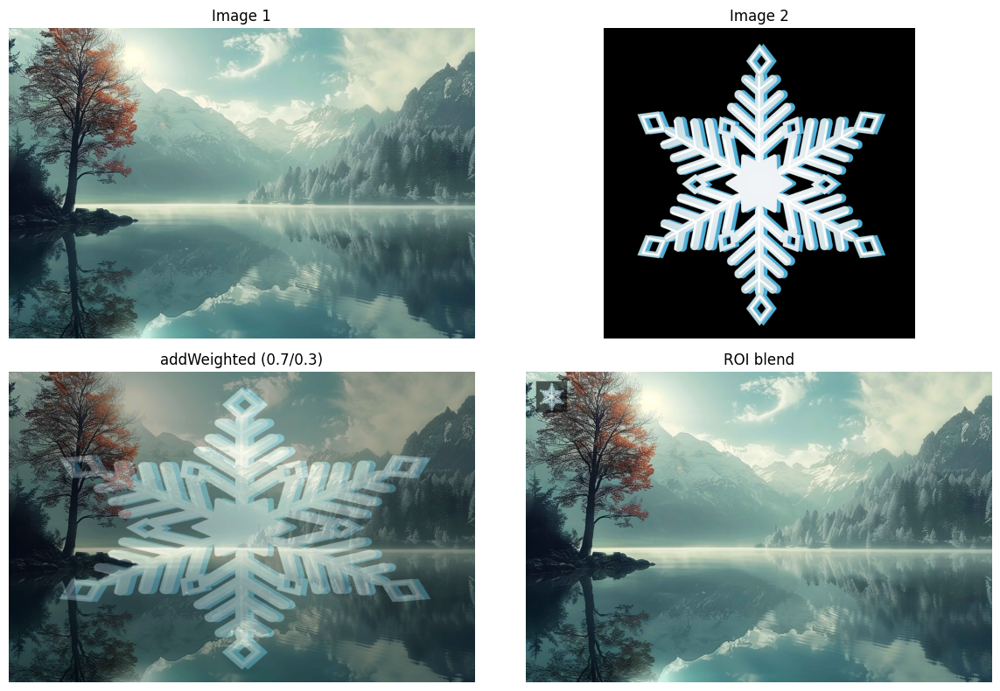

In [ ]:
import cv2
import matplotlib.pyplot as plt

# 1. 讀取兩張影像（請改成自己的檔名）
img1 = cv2.imread("background.png")    # 背景：湖光山色
img2 = cv2.imread("snowflake.png")    # 前景：雪花
if img1 is None or img2 is None:
    raise FileNotFoundError("找不到影像，請確認檔名與路徑")

# 2. OpenCV 讀入為 BGR，matplotlib 顯示需要 RGB，先轉換顏色順序
img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2 = cv2.cvtColor(img2[:, :, :3], cv2.COLOR_BGR2RGB)

# 3. addWeighted 要求兩張影像大小、通道數相同 → 雪花縮放成背景大小
img2_resized = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

# 4. 影像融合：dst = img1*alpha + img2*beta + gamma
alpha, beta, gamma = 0.7, 0.3, 0
blend = cv2.addWeighted(img1, alpha, img2_resized, beta, gamma)

# 5. 進階：雪花縮小後只疊在畫面一角（ROI 融合）
small = cv2.resize(img2, (300, 300))
x, y = 100, 100
roi_blend = img1.copy()
roi = roi_blend[y:y + 300, x:x + 300]
roi_blend[y:y + 300, x:x + 300] = cv2.addWeighted(roi, 0.4, small, 0.6, 0)

# 6. 用 matplotlib 並排顯示
titles = ["Image 1", "Image 2", f"addWeighted ({alpha}/{beta})", "ROI blend"]
images = [img1, img2, blend, roi_blend]

plt.figure(figsize=(12, 8))
for i, (t, im) in enumerate(zip(titles, images), start=1):
    plt.subplot(2, 2, i)
    plt.imshow(im)
    plt.title(t)
    plt.axis("off")
plt.tight_layout()
plt.savefig("blend_result.png", dpi=150)
plt.show()

# 2.邏輯運算與不規則遮罩提取 (Logical Operations & Masking)

使用位元運算實現影像合成
在 OpenCV 中，影像由像素陣列構成。對於常見的 8-bit 影像（數值範圍 $0 \sim 255$）：
* **純黑像素（0）**：二進位為 `00000000`（所有位元皆為 $0$）
* **純白像素（255）**：二進位為 `11111111`（所有位元皆為 $1$）
* **原圖顏色（P）**：介於 $0 \sim 255$ 之間的任意像素值

利用這項特性，位元邏輯運算成為影像**去背、挖空、遮罩（Masking）與圖層無痕拼合**的核心工具。

- `cv2.bitwise_and()`: 位元 AND
- `cv2.bitwise_or()`: 位元 OR
- `cv2.bitwise_xor()`: 位元 XOR
- `cv2.bitwise_not()`: 位元 NOT

## 2.1 影像邏輯運算本質

### 邏輯與 (cv2.bitwise_and)：前景保留與硬遮罩切邊

> **口訣**：有 $0$ 則 $0$，全 $1$ 才出 $1$。

#### 邏輯真值表

| 輸入 A（像素 A） | 輸入 B（像素 B） | 輸出（A AND B） |
| :---: | :---: | :---: |
| $0$ | $0$ | **$0$** |
| $0$ | $1$ | **$0$** |
| $1$ | $0$ | **$0$** |
| $1$ | $1$ | **$1$** |

#### 影像合成意義
* **$P \text{ AND } 0 = 0$（遇黑抹黑）**：任何像素遇到黑色（$0$），直接被挖空塗黑。
* **$P \text{ AND } 255 = P$（遇白保留原色）**：任何像素遇到白色（$255$），完全保留原色。
* **主要用途**：
  * **背景挖洞**：在背景上挖出剛好容納前景主體的純黑區域。
  * **前景萃取**：只取出主體（Logo），其餘周圍底色抹黑。

---

/tmp/ipykernel_2968/1985716432.py:143: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


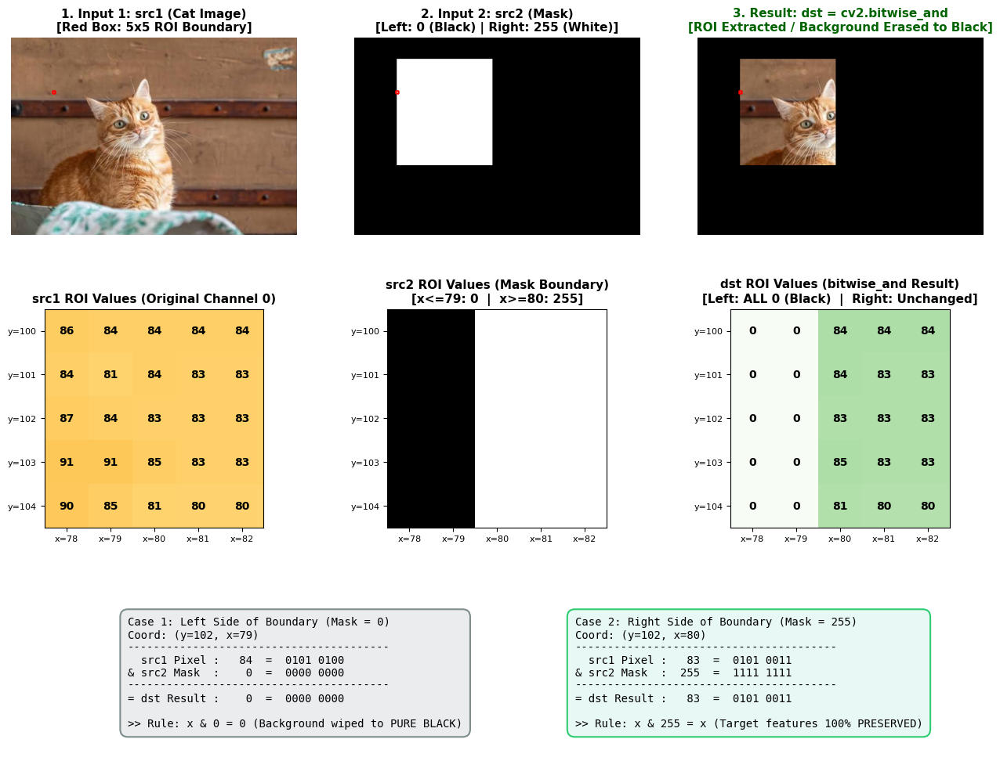

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# =========================================================================
# 1. 讀取或合成橘貓影像
# =========================================================================
src1 = cv2.imread("images.jpg")
if src1 is None:
    # 防呆機制：若無圖則合成一張具有漸層與特徵圖形的測試圖
    H, W = 300, 400
    y, x = np.mgrid[0:H, 0:W]
    src1 = np.zeros((H, W, 3), dtype=np.uint8)
    src1[:, :, 0] = np.clip(50 + 100 * (x / W), 0, 255)
    src1[:, :, 1] = np.clip(100 + 80 * (y / H), 0, 255)
    src1[:, :, 2] = np.clip(200 - 50 * (x / W), 0, 255)
    cv2.circle(src1, (200, 150), 70, (40, 140, 230), -1)

# 2. 建立 Mask 並將 [40:240, 80:260] 設為 255 (純白 ROI 區域)
src2 = np.zeros(src1.shape, dtype=np.uint8)
mask_y1, mask_y2 = 40, 240
mask_x1, mask_x2 = 80, 260
src2[mask_y1:mask_y2, mask_x1:mask_x2, :] = 255

# 3. 執行 bitwise_and 運算 (且運算：提取白框內的貓，黑框外全部抹黑)
dst = cv2.bitwise_and(src1, src2)

# =========================================================================
# 2. 切取橫跨「遮罩邊界」的 5x5 微小局部區域 (ROI)
#    挑選 x: 78~83 (左側 2 格是黑區 0，右側 3 格是白區 255)
# =========================================================================
roi_y, roi_x = 100, 78
roi_h, roi_w = 5, 5

# 取單一通道 (例如 Blue 通道) 用於觀察矩陣數值
src1_roi = src1[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
src2_roi = src2[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
dst_roi  = dst[roi_y:roi_y+roi_h,  roi_x:roi_x+roi_w, 0]

# 在宏觀影像上標註 ROI 紅色小方框
src1_marked = src1.copy()
src2_marked = src2.copy()
dst_marked  = dst.copy()
for img_mark in [src1_marked, src2_marked, dst_marked]:
    cv2.rectangle(img_mark, (roi_x, roi_y), (roi_x+roi_w, roi_y+roi_h), (0, 0, 255), 2)

# =========================================================================
# 3. 繪製三層複合視覺化圖解
# =========================================================================
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 3, height_ratios=[1.0, 1.1, 0.8], hspace=0.38, wspace=0.2)

# -------------------------------------------------------------------------
# 第一層：宏觀影像級運算 (Macro Image Level)
# -------------------------------------------------------------------------
ax0 = fig.add_subplot(gs[0, 0])
ax0.imshow(cv2.cvtColor(src1_marked, cv2.COLOR_BGR2RGB))
ax0.set_title("1. Input 1: src1 (Cat Image)\n[Red Box: 5x5 ROI Boundary]", fontsize=11, fontweight='bold')
ax0.axis('off')

ax1 = fig.add_subplot(gs[0, 1])
ax1.imshow(cv2.cvtColor(src2_marked, cv2.COLOR_BGR2RGB))
ax1.set_title("2. Input 2: src2 (Mask)\n[Left: 0 (Black) | Right: 255 (White)]", fontsize=11, fontweight='bold')
ax1.axis('off')

ax2 = fig.add_subplot(gs[0, 2])
ax2.imshow(cv2.cvtColor(dst_marked, cv2.COLOR_BGR2RGB))
ax2.set_title("3. Result: dst = cv2.bitwise_and\n[ROI Extracted / Background Erased to Black]", fontsize=11, fontweight='bold', color='darkgreen')
ax2.axis('off')

# -------------------------------------------------------------------------
# 第二層：中觀局部放大熱力圖 + 像素數值標註 (Mesoscopic Pixel Matrices)
# -------------------------------------------------------------------------
def draw_pixel_matrix(ax, data, title, colormap='Blues'):
    im = ax.imshow(data, cmap=colormap, vmin=0, vmax=255)
    ax.set_title(title, fontsize=11, fontweight='bold')
    # 在每個像素格子中央寫上數值
    for r in range(data.shape[0]):
        for c in range(data.shape[1]):
            val = int(data[r, c])
            text_color = "white" if val > 140 else "black"
            ax.text(c, r, str(val), ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

    # 標註 X 軸對應的 Mask 區域狀態 (左側 0，右側 255)
    ax.set_xticks(range(data.shape[1]))
    ax.set_yticks(range(data.shape[0]))
    ax.set_xticklabels([f"x={roi_x+c}" for c in range(data.shape[1])], fontsize=8)
    ax.set_yticklabels([f"y={roi_y+r}" for r in range(data.shape[0])], fontsize=8)

ax_m0 = fig.add_subplot(gs[1, 0])
draw_pixel_matrix(ax_m0, src1_roi, "src1 ROI Values (Original Channel 0)", colormap='YlOrBr')

ax_m1 = fig.add_subplot(gs[1, 1])
draw_pixel_matrix(ax_m1, src2_roi, "src2 ROI Values (Mask Boundary)\n[x<=79: 0  |  x>=80: 255]", colormap='gray')

ax_m2 = fig.add_subplot(gs[1, 2])
draw_pixel_matrix(ax_m2, dst_roi, "dst ROI Values (bitwise_and Result)\n[Left: ALL 0 (Black)  |  Right: Unchanged]", colormap='Greens')

# -------------------------------------------------------------------------
# 第三層：微觀 8-bit 二進位計算原理 (Microscopic Binary Level)
# -------------------------------------------------------------------------
ax_b = fig.add_subplot(gs[2, :])
ax_b.axis('off')

# 取邊界處的兩顆像素：一組是 x=79 (遇 0)，一組是 x=80 (遇 255)
p_orig_left  = int(src1_roi[2, 1])   # (y=102, x=79) 黑色區
p_mask_left  = int(src2_roi[2, 1])   # 0
p_dst_left   = int(dst_roi[2, 1])    # 變成 0

p_orig_right = int(src1_roi[2, 2])   # (y=102, x=80) 白色區
p_mask_right = int(src2_roi[2, 2])   # 255
p_dst_right  = int(dst_roi[2, 2])    # 保持原值

text_box_left = (
    f"Case 1: Left Side of Boundary (Mask = 0)\n"
    f"Coord: (y={roi_y+2}, x={roi_x+1})\n"
    f"----------------------------------------\n"
    f"  src1 Pixel :  {p_orig_left:>3d}  =  {format(p_orig_left, '08b')[:4]} {format(p_orig_left, '08b')[4:]}\n"
    f"& src2 Mask  :  {p_mask_left:>3d}  =  0000 0000\n"
    f"----------------------------------------\n"
    f"= dst Result :  {p_dst_left:>3d}  =  0000 0000\n\n"
    f">> Rule: x & 0 = 0 (Background wiped to PURE BLACK)"
)

text_box_right = (
    f"Case 2: Right Side of Boundary (Mask = 255)\n"
    f"Coord: (y={roi_y+2}, x={roi_x+2})\n"
    f"----------------------------------------\n"
    f"  src1 Pixel :  {p_orig_right:>3d}  =  {format(p_orig_right, '08b')[:4]} {format(p_orig_right, '08b')[4:]}\n"
    f"& src2 Mask  :  {p_mask_right:>3d}  =  1111 1111\n"
    f"----------------------------------------\n"
    f"= dst Result :  {p_dst_right:>3d}  =  {format(p_orig_right, '08b')[:4]} {format(p_orig_right, '08b')[4:]}\n\n"
    f">> Rule: x & 255 = x (Target features 100% PRESERVED)"
)

ax_b.text(0.12, 0.90, text_box_left, ha='left', va='top', fontsize=10, family='monospace',
          bbox=dict(boxstyle='round,pad=0.7', facecolor='#eaecee', edgecolor='#7f8c8d', lw=1.5))

ax_b.text(0.58, 0.90, text_box_right, ha='left', va='top', fontsize=10, family='monospace',
          bbox=dict(boxstyle='round,pad=0.7', facecolor='#e8f8f5', edgecolor='#2ecc71', lw=1.5))

plt.tight_layout()
plt.show()


### 邏輯或 (cv2.bitwise_or)：文字浮水印與覆蓋疊加

> **口訣**：有 $1$ 則 $1$，全 $0$ 才出 $0$。

#### 邏輯真值表

| 輸入 A（像素 A） | 輸入 B（像素 B） | 輸出（A OR B） |
| :---: | :---: | :---: |
| $0$ | $0$ | **$0$** |
| $0$ | $1$ | **$1$** |
| $1$ | $0$ | **$1$** |
| $1$ | $1$ | **$1$** |

#### 影像合成意義
* **$P \text{ OR } 0 = P$（遇黑保留原色）**：任何色彩與黑色（$0$）做 OR 運算，原色彩不會失真。
* **$P \text{ OR } 255 = 255$（遇白變純白）**：任何像素遇到白色，直接變成全白。
* **主要用途**：
  * **圖層無痕疊加**：將「已挖黑洞的背景」與「黑底的主體前景」合併。因為黑色（$0$）互不干擾，兩者可以完美融合成一張完整圖片。

---

/tmp/ipykernel_2968/2748824709.py:143: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


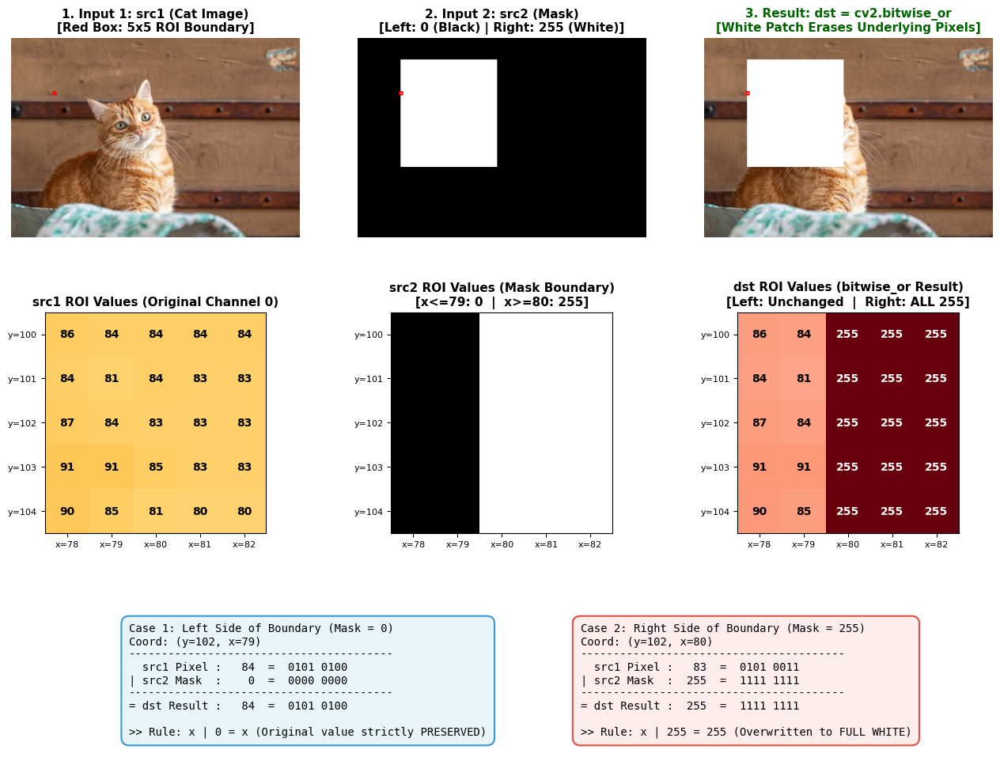

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# =========================================================================
# 1. 讀取或合成橘貓影像
# =========================================================================
src1 = cv2.imread("images.jpg")
if src1 is None:
    # 防呆機制：若無圖則合成一張具有漸層與特徵圖形的測試圖
    H, W = 300, 400
    y, x = np.mgrid[0:H, 0:W]
    src1 = np.zeros((H, W, 3), dtype=np.uint8)
    src1[:, :, 0] = np.clip(50 + 100 * (x / W), 0, 255)
    src1[:, :, 1] = np.clip(100 + 80 * (y / H), 0, 255)
    src1[:, :, 2] = np.clip(200 - 50 * (x / W), 0, 255)
    cv2.circle(src1, (200, 150), 70, (40, 140, 230), -1)

# 2. 建立 Mask 並將 [40:240, 80:260] 設為 255 (純白)
src2 = np.zeros(src1.shape, dtype=np.uint8)
mask_y1, mask_y2 = 40, 240
mask_x1, mask_x2 = 80, 260
src2[mask_y1:mask_y2, mask_x1:mask_x2, :] = 255

# 3. 執行 bitwise_or 運算
dst = cv2.bitwise_or(src1, src2)

# =========================================================================
# 2. 切取橫跨「遮罩邊界」的 5x5 微小局部區域 (ROI)
#    挑選 x: 78~83 (左側 2 格是黑區 0，右側 3 格是白區 255)
# =========================================================================
roi_y, roi_x = 100, 78
roi_h, roi_w = 5, 5

# 為簡化數值觀察，取單一通道 (例如 Blue 通道，或轉灰階)
src1_roi = src1[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
src2_roi = src2[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
dst_roi  = dst[roi_y:roi_y+roi_h,  roi_x:roi_x+roi_w, 0]

# 在宏觀影像上標註 ROI 紅色小方框
src1_marked = src1.copy()
src2_marked = src2.copy()
dst_marked  = dst.copy()
for img_mark in [src1_marked, src2_marked, dst_marked]:
    cv2.rectangle(img_mark, (roi_x, roi_y), (roi_x+roi_w, roi_y+roi_h), (0, 0, 255), 2)

# =========================================================================
# 3. 繪製三層複合視覺化圖解
# =========================================================================
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 3, height_ratios=[1.0, 1.1, 0.8], hspace=0.38, wspace=0.2)

# -------------------------------------------------------------------------
# 第一層：宏觀影像級運算 (Macro Image Level)
# -------------------------------------------------------------------------
ax0 = fig.add_subplot(gs[0, 0])
ax0.imshow(cv2.cvtColor(src1_marked, cv2.COLOR_BGR2RGB))
ax0.set_title("1. Input 1: src1 (Cat Image)\n[Red Box: 5x5 ROI Boundary]", fontsize=11, fontweight='bold')
ax0.axis('off')

ax1 = fig.add_subplot(gs[0, 1])
ax1.imshow(cv2.cvtColor(src2_marked, cv2.COLOR_BGR2RGB))
ax1.set_title("2. Input 2: src2 (Mask)\n[Left: 0 (Black) | Right: 255 (White)]", fontsize=11, fontweight='bold')
ax1.axis('off')

ax2 = fig.add_subplot(gs[0, 2])
ax2.imshow(cv2.cvtColor(dst_marked, cv2.COLOR_BGR2RGB))
ax2.set_title("3. Result: dst = cv2.bitwise_or\n[White Patch Erases Underlying Pixels]", fontsize=11, fontweight='bold', color='darkgreen')
ax2.axis('off')

# -------------------------------------------------------------------------
# 第二層：中觀局部放大熱力圖 + 像素數值標註 (Mesoscopic Pixel Matrices)
# -------------------------------------------------------------------------
def draw_pixel_matrix(ax, data, title, colormap='Blues'):
    im = ax.imshow(data, cmap=colormap, vmin=0, vmax=255)
    ax.set_title(title, fontsize=11, fontweight='bold')
    # 在每個像素格子中央寫上數值
    for r in range(data.shape[0]):
        for c in range(data.shape[1]):
            val = int(data[r, c])
            text_color = "white" if val > 140 else "black"
            ax.text(c, r, str(val), ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

    # 標註 X 軸對應的 Mask 區域狀態 (左側 0，右側 255)
    ax.set_xticks(range(data.shape[1]))
    ax.set_yticks(range(data.shape[0]))
    ax.set_xticklabels([f"x={roi_x+c}" for c in range(data.shape[1])], fontsize=8)
    ax.set_yticklabels([f"y={roi_y+r}" for r in range(data.shape[0])], fontsize=8)

ax_m0 = fig.add_subplot(gs[1, 0])
draw_pixel_matrix(ax_m0, src1_roi, "src1 ROI Values (Original Channel 0)", colormap='YlOrBr')

ax_m1 = fig.add_subplot(gs[1, 1])
draw_pixel_matrix(ax_m1, src2_roi, "src2 ROI Values (Mask Boundary)\n[x<=79: 0  |  x>=80: 255]", colormap='gray')

ax_m2 = fig.add_subplot(gs[1, 2])
draw_pixel_matrix(ax_m2, dst_roi, "dst ROI Values (bitwise_or Result)\n[Left: Unchanged  |  Right: ALL 255]", colormap='Reds')

# -------------------------------------------------------------------------
# 第三層：微觀 8-bit 二進位計算原理 (Microscopic Binary Level)
# -------------------------------------------------------------------------
ax_b = fig.add_subplot(gs[2, :])
ax_b.axis('off')

# 取邊界處的兩顆像素：一組是 x=79 (遇 0)，一組是 x=80 (遇 255)
p_orig_left  = int(src1_roi[2, 1])   # (y=102, x=79) 黑色區
p_mask_left  = int(src2_roi[2, 1])   # 0
p_dst_left   = int(dst_roi[2, 1])    # 保持原值

p_orig_right = int(src1_roi[2, 2])   # (y=102, x=80) 白色區
p_mask_right = int(src2_roi[2, 2])   # 255
p_dst_right  = int(dst_roi[2, 2])    # 變成 255

text_box_left = (
    f"Case 1: Left Side of Boundary (Mask = 0)\n"
    f"Coord: (y={roi_y+2}, x={roi_x+1})\n"
    f"----------------------------------------\n"
    f"  src1 Pixel :  {p_orig_left:>3d}  =  {format(p_orig_left, '08b')[:4]} {format(p_orig_left, '08b')[4:]}\n"
    f"| src2 Mask  :  {p_mask_left:>3d}  =  0000 0000\n"
    f"----------------------------------------\n"
    f"= dst Result :  {p_dst_left:>3d}  =  {format(p_dst_left, '08b')[:4]} {format(p_dst_left, '08b')[4:]}\n\n"
    f">> Rule: x | 0 = x (Original value strictly PRESERVED)"
)

text_box_right = (
    f"Case 2: Right Side of Boundary (Mask = 255)\n"
    f"Coord: (y={roi_y+2}, x={roi_x+2})\n"
    f"----------------------------------------\n"
    f"  src1 Pixel :  {p_orig_right:>3d}  =  {format(p_orig_right, '08b')[:4]} {format(p_orig_right, '08b')[4:]}\n"
    f"| src2 Mask  :  {p_mask_right:>3d}  =  1111 1111\n"
    f"----------------------------------------\n"
    f"= dst Result :  {p_dst_right:>3d}  =  1111 1111\n\n"
    f">> Rule: x | 255 = 255 (Overwritten to FULL WHITE)"
)

ax_b.text(0.12, 0.90, text_box_left, ha='left', va='top', fontsize=10, family='monospace',
          bbox=dict(boxstyle='round,pad=0.7', facecolor='#e8f4f8', edgecolor='#3498db', lw=1.5))

ax_b.text(0.58, 0.90, text_box_right, ha='left', va='top', fontsize=10, family='monospace',
          bbox=dict(boxstyle='round,pad=0.7', facecolor='#fdedec', edgecolor='#e74c3c', lw=1.5))

plt.tight_layout()
plt.show()


### 邏輯非 (cv2.bitwise_not)：黑白反相與 OCR 前處理

> **口訣**：相同為 $0$，相異為 $1$。

#### 邏輯真值表

| 輸入 A（像素 A） | 輸入 B（像素 B） | 輸出（A XOR B） |
| :---: | :---: | :---: |
| $0$ | $0$ | **$0$** |
| $0$ | $1$ | **$1$** |
| $1$ | $0$ | **$1$** |
| $1$ | $1$ | **$0$** |

#### 影像合成意義
* **$P \text{ XOR } P = 0$（重疊處抹黑消除）**：兩張圖相同、重疊的部分運算後歸零變黑。
* **$P \text{ XOR } 0 = P$（非重疊區保留原樣）**：僅有一方有圖案的區域完整保留。
* **$P \text{ XOR } 255 = 255 - P$（色彩反轉）**：相當於負片效果。
* **主要用途**：
  * **差異檢測**：比較兩張圖片哪裡不同，相同區塊會直接變黑消去。
  * **形狀互斥挖空**：合併兩個形狀時，交集處自動挖空。

---

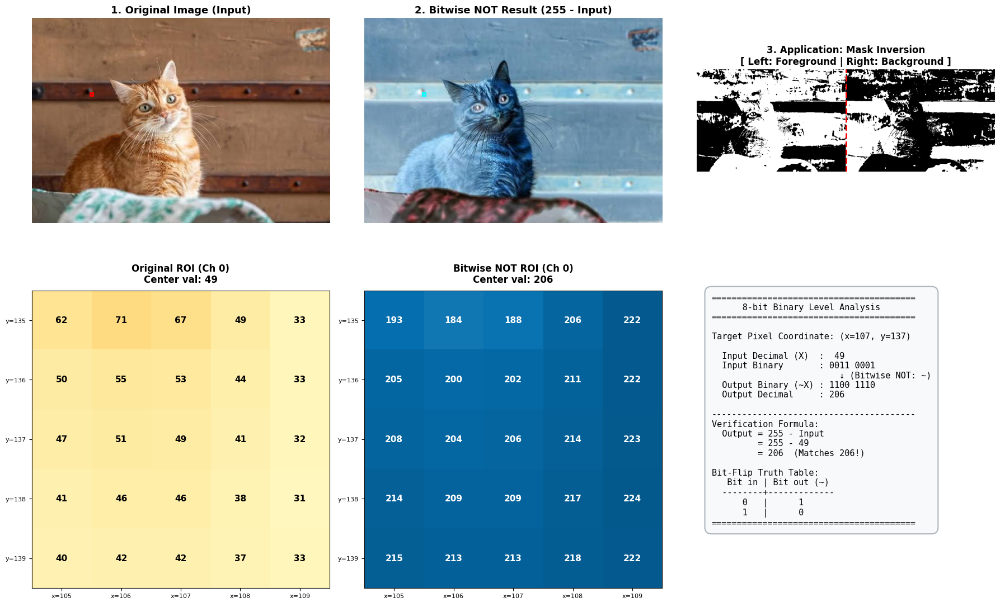

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

# ==============================================================================
# 0. 影像防呆載入機制（若無 images.jpg 則自動合成）
# ==============================================================================
img_path = 'images.jpg'
if not os.path.exists(img_path):
    print("⚠️ [images.jpg] not found. Synthesizing a demo image...")
    syn_img = np.zeros((300, 300, 3), dtype=np.uint8)
    syn_img[:] = (80, 50, 30)  # 木箱深褐色背景
    # 畫橘貓臉
    cv2.ellipse(syn_img, (150, 160), (100, 80), 0, 0, 360, (30, 140, 255), -1)
    # 貓眼 (黃綠色)
    cv2.circle(syn_img, (110, 140), 18, (0, 220, 220), -1)
    cv2.circle(syn_img, (190, 140), 18, (0, 220, 220), -1)
    # 瞳孔 (黑)
    cv2.circle(syn_img, (110, 140), 7, (20, 20, 20), -1)
    cv2.circle(syn_img, (190, 140), 7, (20, 20, 20), -1)
    cv2.imwrite(img_path, syn_img)

src = cv2.imread(img_path)

# ==============================================================================
# 1. 執行 cv2.bitwise_not
# ==============================================================================
not_result = cv2.bitwise_not(src)

# 示範實戰：建立二值化遮罩並做 NOT 運算（前景遮罩 -> 背景遮罩）
gray = cv2.cvtColor(src, cv2.COLOR_BGR2GRAY)
_, mask_foreground = cv2.threshold(gray, 110, 255, cv2.THRESH_BINARY)
mask_background = cv2.bitwise_not(mask_foreground)

# ==============================================================================
# 2. 定義 5x5 ROI 觀察區域（選在貓臉眼部邊界，亮暗對比較為明顯）
# ==============================================================================
roi_y, roi_x = 135, 105
roi_h, roi_w = 5, 5

# 取 Channel 0 (B 通道) 進行二進位與矩陣詳細分析
roi_src = src[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
roi_not = not_result[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]

# ==============================================================================
# 3. 繪圖函式：繪製 5x5 像素數值矩陣熱力圖
# ==============================================================================
def draw_pixel_matrix(ax, matrix, title, cmap='Blues'):
    im = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=255)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)

    # 標註每一格像素數值，依背景深淺自動切換字體顏色
    for r in range(matrix.shape[0]):
        for c in range(matrix.shape[1]):
            val = int(matrix[r, c])
            text_color = "white" if val > 130 else "black"
            ax.text(c, r, f"{val}", ha="center", va="center",
                    color=text_color, fontsize=11, fontweight='bold')

    ax.set_xticks(range(matrix.shape[1]))
    ax.set_yticks(range(matrix.shape[0]))
    ax.set_xticklabels([f"x={roi_x + c}" for c in range(matrix.shape[1])], fontsize=8)
    ax.set_yticklabels([f"y={roi_y + r}" for r in range(matrix.shape[0])], fontsize=8)
    return im

# ==============================================================================
# 4. Matplotlib 綜合畫布（英文標題）
# ==============================================================================
fig = plt.figure(figsize=(18, 12))

# --- 第一層：宏觀影像比較 ---
ax1 = plt.subplot2grid((2, 3), (0, 0))
ax1.imshow(cv2.cvtColor(src, cv2.COLOR_BGR2RGB))
rect1 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='red', facecolor='none')
ax1.add_patch(rect1)
ax1.set_title("1. Original Image (Input)", fontsize=13, fontweight='bold')
ax1.axis('off')

ax2 = plt.subplot2grid((2, 3), (0, 1))
ax2.imshow(cv2.cvtColor(not_result, cv2.COLOR_BGR2RGB))
rect2 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='cyan', facecolor='none')
ax2.add_patch(rect2)
ax2.set_title("2. Bitwise NOT Result (255 - Input)", fontsize=13, fontweight='bold')
ax2.axis('off')

ax3 = plt.subplot2grid((2, 3), (0, 2))
# 將前景遮罩與反轉背景遮罩並排展示
combined_mask = np.hstack((mask_foreground, mask_background))
ax3.imshow(combined_mask, cmap='gray', vmin=0, vmax=255)
ax3.axvline(x=src.shape[1], color='red', linestyle='--', linewidth=2)
ax3.set_title("3. Application: Mask Inversion\n[ Left: Foreground | Right: Background ]", fontsize=12, fontweight='bold')
ax3.axis('off')

# --- 第二層：中間 5x5 ROI 數值微觀圖解 ---
ax4 = plt.subplot2grid((2, 3), (1, 0))
draw_pixel_matrix(ax4, roi_src, f"Original ROI (Ch 0)\nCenter val: {roi_src[2, 2]}", cmap='YlOrBr')

ax5 = plt.subplot2grid((2, 3), (1, 1))
draw_pixel_matrix(ax5, roi_not, f"Bitwise NOT ROI (Ch 0)\nCenter val: {roi_not[2, 2]}", cmap='PuBu')

# --- 第三層：底層二進位計算拆解看板 ---
ax6 = plt.subplot2grid((2, 3), (1, 2))
ax6.axis('off')

# 取出中心像素進行二進位數學拆解
v_in = int(roi_src[2, 2])
v_out = int(roi_not[2, 2])

bin_in = f"{v_in:08b}"
bin_out = f"{v_out:08b}"

analysis_text = (
    "========================================\n"
    "      8-bit Binary Level Analysis       \n"
    "========================================\n\n"
    f"Target Pixel Coordinate: (x={roi_x+2}, y={roi_y+2})\n\n"
    f"  Input Decimal (X)  : {v_in:>3d}\n"
    f"  Input Binary       : {bin_in[:4]} {bin_in[4:]}\n"
    "                         ↓ (Bitwise NOT: ~)\n"
    f"  Output Binary (~X) : {bin_out[:4]} {bin_out[4:]}\n"
    f"  Output Decimal     : {v_out:>3d}\n\n"
    "----------------------------------------\n"
    "Verification Formula:\n"
    f"  Output = 255 - Input\n"
    f"         = 255 - {v_in}\n"
    f"         = {255 - v_in}  (Matches {v_out}!)\n\n"
    "Bit-Flip Truth Table:\n"
    "   Bit in | Bit out (~)\n"
    "  --------+-------------\n"
    "      0   |      1      \n"
    "      1   |      0      \n"
    "========================================"
)

ax6.text(0.05, 0.95, analysis_text, transform=ax6.transAxes,
         fontsize=11, family='monospace', verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.8', facecolor='#f8f9fa', edgecolor='#adb5bd', linewidth=1.5))

plt.tight_layout()
plt.show()


### 邏輯互斥或 (cv2.bitwise_xor)：雙圖對稱加密與差分可視化

> **口訣**：$0$ 變 $1$，$1$ 變 $0$。

#### 邏輯真值表

| 輸入 A（像素 A） | 輸出（NOT A） |
| :---: | :---: |
| $0$ | **$1$** |
| $1$ | **$0$** |

#### 影像合成意義
* **$\text{NOT } 0 = 255$**：黑色區域翻轉為純白。
* **$\text{NOT } 255 = 0$**：白色區域翻轉為純黑。
* **主要用途**：
  * **反向遮罩（Mask Invert）**：將遮罩黑白顛倒。通常與二值化搭配，快速在「保留前景」與「保留背景」兩種遮罩間切換。


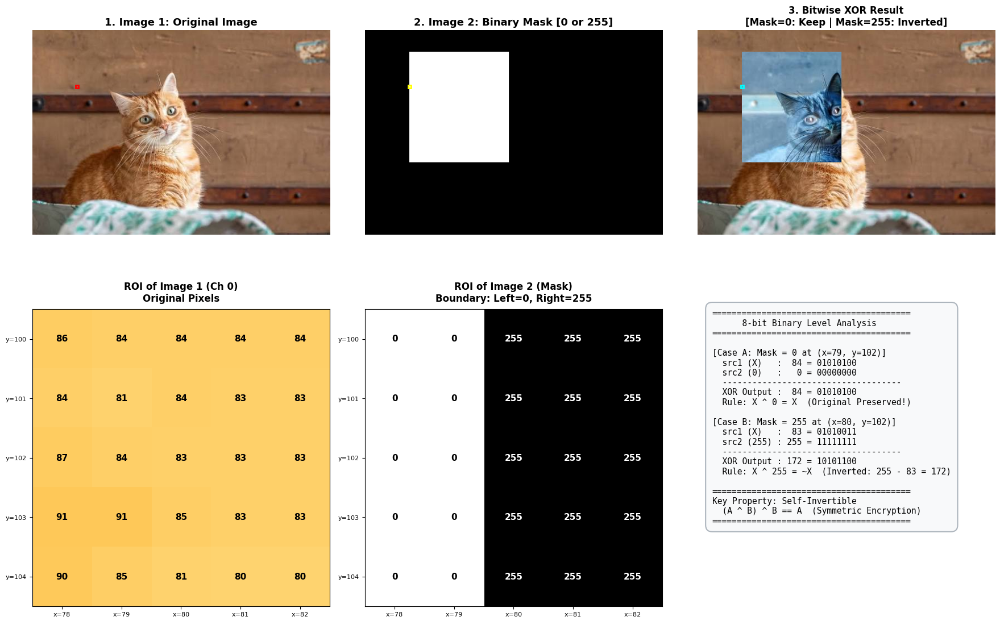

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

# ==============================================================================
# 0. 影像防呆載入機制（若無 images.jpg 則自動合成）
# ==============================================================================
img_path = 'images.jpg'
if not os.path.exists(img_path):
    print("⚠️ [images.jpg] not found. Synthesizing a demo image...")
    syn_img = np.zeros((300, 300, 3), dtype=np.uint8)
    syn_img[:] = (80, 50, 30)  # 木箱深褐色背景
    cv2.ellipse(syn_img, (150, 160), (100, 80), 0, 0, 360, (30, 140, 255), -1)  # 橘貓臉
    cv2.circle(syn_img, (110, 140), 18, (0, 220, 220), -1)  # 貓眼 (黃綠)
    cv2.circle(syn_img, (190, 140), 18, (0, 220, 220), -1)
    cv2.circle(syn_img, (110, 140), 7, (20, 20, 20), -1)    # 瞳孔 (黑)
    cv2.circle(syn_img, (190, 140), 7, (20, 20, 20), -1)
    cv2.imwrite(img_path, syn_img)

src1 = cv2.imread(img_path)

# ==============================================================================
# 1. 建立具有對比交界的二值測試遮罩 (src2)
# ==============================================================================
# 建立一個中央為純白 (255)、外圍為黑 (0) 的遮罩
src2 = np.zeros_like(src1)
mask_y1, mask_y2 = 40, 240
mask_x1, mask_x2 = 80, 260
src2[mask_y1:mask_y2, mask_x1:mask_x2, :] = 255

# 執行 Bitwise XOR 運算
xor_result = cv2.bitwise_xor(src1, src2)

# ==============================================================================
# 2. 定義 5x5 ROI 觀察區域（跨越遮罩交界 x=80）
# ==============================================================================
# 橫跨 x=80 邊界：左側 x in [78, 79] 為遮罩外 (0)，右側 x in [80, 81, 82] 為遮罩內 (255)
roi_y, roi_x = 100, 78
roi_h, roi_w = 5, 5

# 取 Channel 0 (B 通道) 分析
roi_src1 = src1[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
roi_src2 = src2[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]
roi_xor  = xor_result[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w, 0]

# ==============================================================================
# 3. 繪圖輔助函式：繪製 5x5 像素數值矩陣
# ==============================================================================
def draw_pixel_matrix(ax, matrix, title, cmap='Blues'):
    im = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=255)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)

    for r in range(matrix.shape[0]):
        for c in range(matrix.shape[1]):
            val = int(matrix[r, c])
            text_color = "white" if val > 130 else "black"
            ax.text(c, r, f"{val}", ha="center", va="center",
                    color=text_color, fontsize=11, fontweight='bold')

    ax.set_xticks(range(matrix.shape[1]))
    ax.set_yticks(range(matrix.shape[0]))
    ax.set_xticklabels([f"x={roi_x + c}" for c in range(matrix.shape[1])], fontsize=8)
    ax.set_yticklabels([f"y={roi_y + r}" for r in range(matrix.shape[0])], fontsize=8)
    return im

# ==============================================================================
# 4. Matplotlib 綜合畫布（英文標題）
# ==============================================================================
fig = plt.figure(figsize=(18, 12))

# --- 第一層：宏觀影像展示 ---
ax1 = plt.subplot2grid((2, 3), (0, 0))
ax1.imshow(cv2.cvtColor(src1, cv2.COLOR_BGR2RGB))
rect1 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='red', facecolor='none')
ax1.add_patch(rect1)
ax1.set_title("1. Image 1: Original Image", fontsize=13, fontweight='bold')
ax1.axis('off')

ax2 = plt.subplot2grid((2, 3), (0, 1))
ax2.imshow(cv2.cvtColor(src2, cv2.COLOR_BGR2RGB))
rect2 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='yellow', facecolor='none')
ax2.add_patch(rect2)
ax2.set_title("2. Image 2: Binary Mask [0 or 255]", fontsize=13, fontweight='bold')
ax2.axis('off')

ax3 = plt.subplot2grid((2, 3), (0, 2))
ax3.imshow(cv2.cvtColor(xor_result, cv2.COLOR_BGR2RGB))
rect3 = patches.Rectangle((roi_x, roi_y), roi_w, roi_h, linewidth=2, edgecolor='cyan', facecolor='none')
ax3.add_patch(rect3)
ax3.set_title("3. Bitwise XOR Result\n[Mask=0: Keep | Mask=255: Inverted]", fontsize=12, fontweight='bold')
ax3.axis('off')

# --- 第二層：中間 5x5 ROI 數值微觀熱力圖 ---
ax4 = plt.subplot2grid((2, 3), (1, 0))
draw_pixel_matrix(ax4, roi_src1, "ROI of Image 1 (Ch 0)\nOriginal Pixels", cmap='YlOrBr')

ax5 = plt.subplot2grid((2, 3), (1, 1))
draw_pixel_matrix(ax5, roi_src2, "ROI of Image 2 (Mask)\nBoundary: Left=0, Right=255", cmap='Greys')

# --- 第三層：底層二進位計算拆解看板 ---
ax6 = plt.subplot2grid((2, 3), (1, 2))
ax6.axis('off')

# 取樣兩個具代表性的點：
# 點 A: 遮罩為 0 (左側 x=79, 即 col 1, row 2)
v1_A = int(roi_src1[2, 1])
v2_A = int(roi_src2[2, 1])
out_A = int(roi_xor[2, 1])

# 點 B: 遮罩為 255 (右側 x=80, 即 col 2, row 2)
v1_B = int(roi_src1[2, 2])
v2_B = int(roi_src2[2, 2])
out_B = int(roi_xor[2, 2])

analysis_text = (
    "========================================\n"
    "      8-bit Binary Level Analysis       \n"
    "========================================\n\n"
    f"[Case A: Mask = 0 at (x={roi_x+1}, y={roi_y+2})]\n"
    f"  src1 (X)   : {v1_A:>3d} = {v1_A:08b}\n"
    f"  src2 (0)   : {v2_A:>3d} = {v2_A:08b}\n"
    "  ------------------------------------\n"
    f"  XOR Output : {out_A:>3d} = {out_A:08b}\n"
    f"  Rule: X ^ 0 = X  (Original Preserved!)\n\n"
    f"[Case B: Mask = 255 at (x={roi_x+2}, y={roi_y+2})]\n"
    f"  src1 (X)   : {v1_B:>3d} = {v1_B:08b}\n"
    f"  src2 (255) : {v2_B:>3d} = {v2_B:08b}\n"
    "  ------------------------------------\n"
    f"  XOR Output : {out_B:>3d} = {out_B:08b}\n"
    f"  Rule: X ^ 255 = ~X  (Inverted: 255 - {v1_B} = {out_B})\n\n"
    "========================================\n"
    "Key Property: Self-Invertible\n"
    "  (A ^ B) ^ B == A  (Symmetric Encryption)\n"
    "========================================"
)

ax6.text(0.05, 0.95, analysis_text, transform=ax6.transAxes,
         fontsize=10.5, family='monospace', verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.8', facecolor='#f8f9fa', edgecolor='#adb5bd', linewidth=1.5))

plt.tight_layout()
plt.show()


##  2.2 遮罩拓撲本質與非對稱性合成


### 遮罩概念：0 與 255 的幾何意義（Source 提供內容，Mask 提供拓撲）

In [ ]:
import cv2
import numpy as np

img1 = np.ones((4,5),dtype=np.uint8) * 8
img2 = np.ones((4,5),dtype=np.uint8) * 9
mask = np.zeros((4,5),dtype=np.uint8)
mask[1:3,1:4] = 255
dst = np.random.randint(0,256,(4,5),np.uint8)
print("img1 = \n",img1)
print("img2 = \n",img2)
print("mask = \n",mask)
print("最初值 dst =\n",dst)
dst = cv2.add(img1,img2,mask=mask)
print("結果值 dst =\n",dst)

img1 = 
 [[8 8 8 8 8]
 [8 8 8 8 8]
 [8 8 8 8 8]
 [8 8 8 8 8]]
img2 = 
 [[9 9 9 9 9]
 [9 9 9 9 9]
 [9 9 9 9 9]
 [9 9 9 9 9]]
mask = 
 [[  0   0   0   0   0]
 [  0 255 255 255   0]
 [  0 255 255 255   0]
 [  0   0   0   0   0]]
最初值 dst =
 [[ 32  58 108 229 211]
 [214 233  22   0   4]
 [150  55 239 244 133]
 [176 112 231 209 193]]
結果值 dst =
 [[ 0  0  0  0  0]
 [ 0 17 17 17  0]
 [ 0 17 17 17  0]
 [ 0  0  0  0  0]]


### 標準影像合成三部曲流程架構（挖空、提取、OR 合併）

```text
[ Logo 原圖 ] ──(灰階與二值化)──> [ Mask 遮罩: 前景黑(0), 底色白(255) ]
                                         │
                                         ├──(cv2.bitwise_not)──> [ Mask_inv: 前景白(255), 底色黑(0) ]
                                         │                                │
[ 背景局部 ROI ] ─┐                     │                                │
                  ├───────(cv2.bitwise_and)                        ├───────(cv2.bitwise_and)
                  │   (遇 0 挖黑洞，遇 255 保留)                     │   (遇 255 保留 Logo 色，遇 0 變黑)
                  ▼                                                ▼
          [ 挖出黑洞的背景 ]                                [ 純黑底色的 Logo 前景 ]
                  │                                                │
                  └────────────────────────┬───────────────────────┘
                                           ▼
                                  (cv2.bitwise_or)
                          (遇 0 色彩不干擾，完美填入拼接)
                                           ▼
                                     [ 最終合成影像 ]

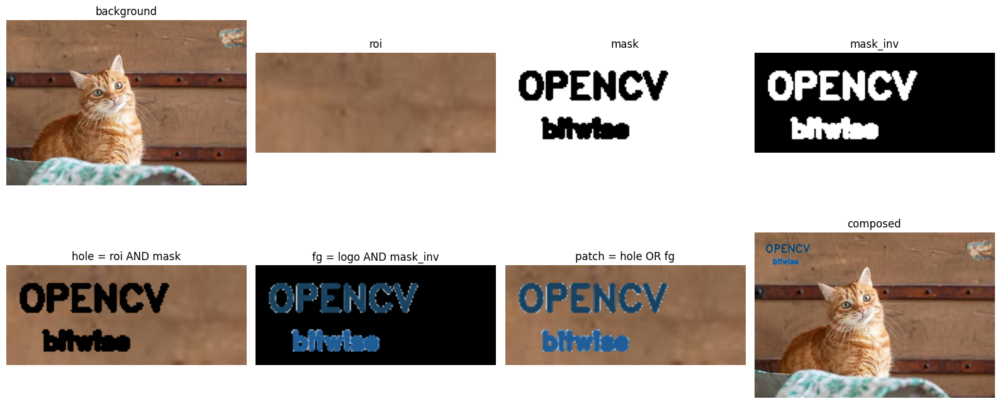

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀背景圖
BASE = cv2.imread("images.jpg")
assert BASE is not None, "讀不到 images.jpg,請確認路徑"
BH, BW = BASE.shape[:2]

# 2. 產生 Logo:白底 255 + 深色字
w = min(max(96, int(BW * 0.30)), BW, int(BH / 0.42))
h = int(w * 0.42)
LOGO = np.full((h, w, 3), 255, np.uint8)
cv2.putText(LOGO, "OPENCV", (int(w * 0.05), int(h * 0.45)),
            cv2.FONT_HERSHEY_DUPLEX, w / 200, (96, 66, 24), 2, cv2.LINE_AA)
cv2.putText(LOGO, "bitwise", (int(w * 0.15), int(h * 0.85)),
            cv2.FONT_HERSHEY_DUPLEX, w / 300, (150, 92, 32), 2, cv2.LINE_AA)

# 3. threshold:白底 255、字 0
gray = cv2.cvtColor(LOGO, cv2.COLOR_BGR2GRAY)
_, mask = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY)

# 4. bitwise_not:字 255、底 0
mask_inv = cv2.bitwise_not(mask)

# 5. 取背景 ROI(尺寸 = Logo)
y0 = max(0, min(int(BH * 0.04), BH - h))
x0 = max(0, min(int(BW * 0.03), BW - w))
roi = BASE[y0:y0 + h, x0:x0 + w].copy()

# 6. and / and / or
hole = cv2.bitwise_and(roi, roi, mask=mask)          # 背景挖出字的洞
fg   = cv2.bitwise_and(LOGO, LOGO, mask=mask_inv)    # 只留字
patch = cv2.bitwise_or(hole, fg)                     # 合併

composed = BASE.copy()
composed[y0:y0 + h, x0:x0 + w] = patch

# 7. matplotlib 顯示
rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
items = [("background", rgb(BASE)),   ("roi", rgb(roi)),
         ("mask", mask),              ("mask_inv", mask_inv),
         ("hole = roi AND mask", rgb(hole)),
         ("fg = logo AND mask_inv", rgb(fg)),
         ("patch = hole OR fg", rgb(patch)),
         ("composed", rgb(composed))]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (title, im) in zip(axes.ravel(), items):
    ax.imshow(im, cmap="gray" if im.ndim == 2 else None, vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


### 邏輯運算的非對稱性（前景遮罩保留與提取）

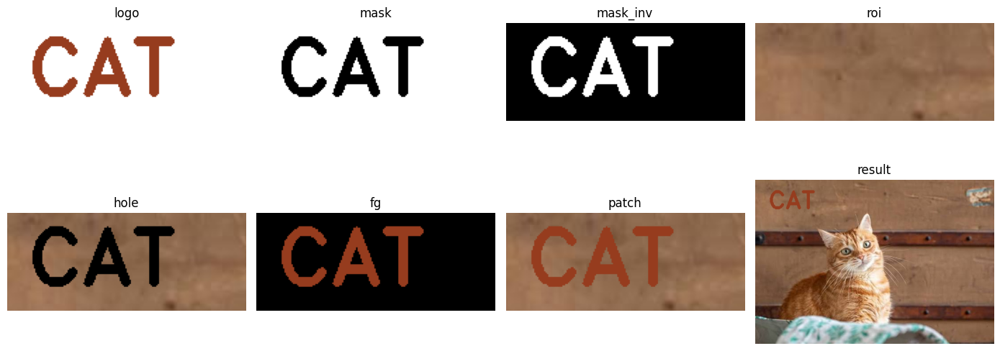

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀貓咪圖
cat = cv2.imread("images.jpg")
assert cat is not None, "讀不到 images.jpg,請確認路徑"

# 2. 做一個白底深色字的 Logo
h, w = 70, 170
logo = np.full((h, w, 3), 255, np.uint8)
cv2.putText(logo, "CAT", (15, 50), cv2.FONT_HERSHEY_DUPLEX, 1.8, (30, 60, 150), 3)

# 3. mask:字 = 0、底 = 255;mask_inv:字 = 255、底 = 0
gray = cv2.cvtColor(logo, cv2.COLOR_BGR2GRAY)
_, mask = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY)
mask_inv = cv2.bitwise_not(mask)

# 4. 取貓圖左上角的木牆當 ROI(大小要和 Logo 一樣)
y0, x0 = 15, 15
roi = cat[y0:y0 + h, x0:x0 + w]

# 5. and / and / or
hole  = cv2.bitwise_and(roi,  roi,  mask=mask)       # 木牆挖出字形的洞
fg    = cv2.bitwise_and(logo, logo, mask=mask_inv)   # 只留字
patch = cv2.bitwise_or(hole, fg)                     # 合併

# 6. 貼回貓圖
result = cat.copy()
result[y0:y0 + h, x0:x0 + w] = patch

# 7. 顯示
rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
items = [("logo", rgb(logo)), ("mask", mask), ("mask_inv", mask_inv),
         ("roi", rgb(roi)), ("hole", rgb(hole)), ("fg", rgb(fg)),
         ("patch", rgb(patch)), ("result", rgb(result))]

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (title, im) in zip(axes.ravel(), items):
    ax.imshow(im, cmap="gray" if im.ndim == 2 else None, vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


## 2.3 不規則區域提取（Arbitrary ROI Extraction）


### 多邊形繪製選型：cv2.fillPoly vs cv2.fillConvexPoly

### 基礎實戰：三層視覺化不規則多邊形提取（含 5×5 邊界微觀矩陣）

/tmp/ipykernel_2968/1124211179.py:155: UserWarning: Glyph 25273 (\N{CJK UNIFIED IDEOGRAPH-62B9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2968/1124211179.py:155: UserWarning: Glyph 40657 (\N{CJK UNIFIED IDEOGRAPH-9ED1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2968/1124211179.py:155: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2968/1124211179.py:155: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2968/1124211179.py:155: UserWarning: Glyph 20445 (\N{CJK UNIFIED IDEOGRAPH-4FDD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2968/1124211179.py:155: UserWarning: Glyph 30041 (\N{CJK UNIFIED IDEOGRAPH-7559}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Gly

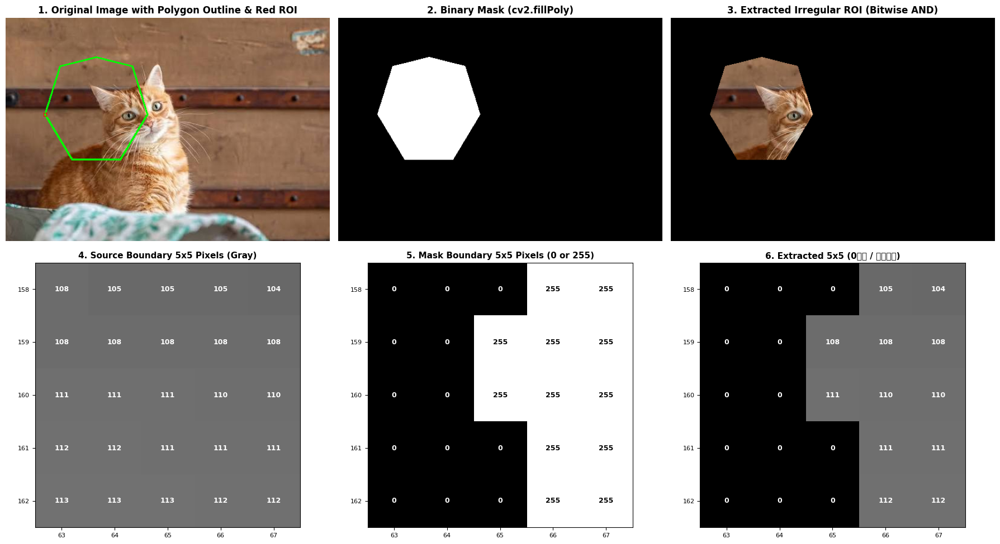

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

# =========================================================================
# 1. 自包含影像載入與合成防呆機制
# =========================================================================
IMAGE_PATH = 'images.jpg'
if not os.path.exists(IMAGE_PATH):
  H, W = 300, 300
  mock_bgr = np.zeros((H, W, 3), dtype=np.uint8)
  mock_bgr[:, :] = [30, 50, 80]  # 木箱深褐色背景
  cv2.circle(mock_bgr, (150, 150), 90, (30, 140, 255), -1)  # 橘貓臉
  cv2.circle(mock_bgr, (115, 130), 20, (0, 220, 220), -1)  # 貓眼
  cv2.circle(mock_bgr, (185, 130), 20, (0, 220, 220), -1)
  cv2.circle(mock_bgr, (115, 130), 8, (20, 20, 20), -1)  # 瞳孔
  cv2.circle(mock_bgr, (185, 130), 8, (20, 20, 20), -1)
  cv2.imwrite(IMAGE_PATH, mock_bgr)

img_bgr = cv2.imread(IMAGE_PATH, cv2.IMREAD_COLOR)
H, W, _ = img_bgr.shape

# =========================================================================
# 2. 定義不規則多邊形頂點 (例如：貼合貓頭與耳朵的 7 邊形)
# =========================================================================
# 注意：OpenCV 座標順序為 (x, y)，即 (col, row)
polygon_vertices = np.array(
    [
        [150, 65],  # 頭頂中點
        [210, 80],  # 右耳尖
        [235, 160],  # 右臉頰
        [190, 235],  # 下巴右側
        [110, 235],  # 下巴左側
        [65, 160],  # 左臉頰
        [90, 80],  # 左耳尖
    ],
    dtype=np.int32,
)

# 依規範安全 reshape 為 (-1, 1, 2)
pts = polygon_vertices.reshape((-1, 1, 2))

# =========================================================================
# 3. 建立單通道二值遮罩 (uint8)
# =========================================================================
mask = np.zeros((H, W), dtype=np.uint8)
# cv2.fillPoly 要求第一個參數為遮罩，第二個參數為多邊形列表 [pts]
cv2.fillPoly(mask, [pts], color=255)

# 提取不規則區域
extracted_bgr = cv2.bitwise_and(img_bgr, img_bgr, mask=mask)

# =========================================================================
# 4. 微觀 5x5 ROI 矩陣切片 (選在左臉頰多邊形交界邊界處：x=63~67, y=158~162)
# =========================================================================
roi_y, roi_x = 158, 63
roi_h, roi_w = 5, 5

src_roi_gray = cv2.cvtColor(
    img_bgr[roi_y : roi_y + roi_h, roi_x : roi_x + roi_w], cv2.COLOR_BGR2GRAY
)
mask_roi = mask[roi_y : roi_y + roi_h, roi_x : roi_x + roi_w]
dst_roi_gray = cv2.cvtColor(
    extracted_bgr[roi_y : roi_y + roi_h, roi_x : roi_x + roi_w],
    cv2.COLOR_BGR2GRAY,
)


def draw_matrix_annotated(ax, data, title, is_binary=False):
  v_max = 255
  ax.imshow(data, cmap='gray', vmin=0, vmax=v_max)
  ax.set_title(title, fontsize=11, fontweight='bold')
  for r in range(data.shape[0]):
    for c in range(data.shape[1]):
      val = data[r, c]
      text_color = 'black' if val > 130 else 'white'
      ax.text(
          c,
          r,
          str(val),
          ha='center',
          va='center',
          color=text_color,
          fontsize=9,
          fontweight='bold',
      )
  ax.set_xticks(range(roi_w))
  ax.set_yticks(range(roi_h))
  ax.set_xticklabels([f'{roi_x + c}' for c in range(roi_w)], fontsize=8)
  ax.set_yticklabels([f'{roi_y + r}' for r in range(roi_h)], fontsize=8)


# =========================================================================
# 5. 三層視覺化呈現 (上排：宏觀視覺；下排：微觀邊界 5x5 像素數值)
# =========================================================================
fig = plt.figure(figsize=(18, 10))

# [上排 1] 原圖 + 多邊形輪廓標註
ax1 = plt.subplot2grid((2, 3), (0, 0))
annotated_bgr = img_bgr.copy()
cv2.polylines(
    annotated_bgr, [pts], isClosed=True, color=(0, 255, 0), thickness=2
)
# 畫出 5x5 微觀觀察紅框
cv2.rectangle(
    annotated_bgr,
    (roi_x, roi_y),
    (roi_x + roi_w, roi_y + roi_h),
    (0, 0, 255),
    1,
)
ax1.imshow(cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB))
ax1.set_title(
    '1. Original Image with Polygon Outline & Red ROI',
    fontsize=12,
    fontweight='bold',
)
ax1.axis('off')

# [上排 2] 二值多邊形 Mask
ax2 = plt.subplot2grid((2, 3), (0, 1))
ax2.imshow(mask, cmap='gray', vmin=0, vmax=255)
ax2.set_title(
    '2. Binary Mask (cv2.fillPoly)', fontsize=12, fontweight='bold'
)
ax2.axis('off')

# [上排 3] 提取結果
ax3 = plt.subplot2grid((2, 3), (0, 2))
ax3.imshow(cv2.cvtColor(extracted_bgr, cv2.COLOR_BGR2RGB))
ax3.set_title(
    '3. Extracted Irregular ROI (Bitwise AND)', fontsize=12, fontweight='bold'
)
ax3.axis('off')

# [下排 1] 原圖局部灰階數值矩陣
ax4 = plt.subplot2grid((2, 2 if False else 3), (1, 0))
draw_matrix_annotated(
    ax4, src_roi_gray, '4. Source Boundary 5x5 Pixels (Gray)'
)

# [下排 2] Mask 局部二值數值矩陣
ax5 = plt.subplot2grid((2, 3), (1, 1))
draw_matrix_annotated(
    ax5, mask_roi, '5. Mask Boundary 5x5 Pixels (0 or 255)', is_binary=True
)

# [下排 3] 提取結果局部數值矩陣 (AND 運算驗證)
ax6 = plt.subplot2grid((2, 3), (1, 2))
draw_matrix_annotated(
    ax6, dst_roi_gray, '6. Extracted 5x5 (0抹黑 / 原值保留)'
)

plt.tight_layout()
plt.show()


### 進階實戰：凹多邊形與多區域挖洞（複變孔洞 Compound Mask）

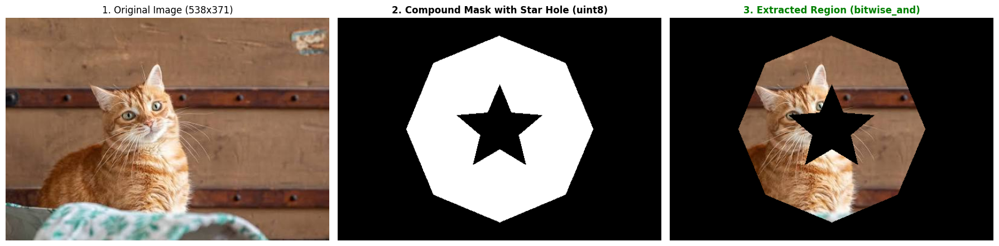

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. 讀取影像
IMAGE_PATH = 'images.jpg'

if not os.path.exists(IMAGE_PATH):
  # 若無影像則建立測試圖
  mock = np.zeros((300, 300, 3), dtype=np.uint8)
  mock[:, :] = [30, 50, 80]
  cv2.circle(mock, (150, 150), 90, (30, 140, 255), -1)
  cv2.imwrite(IMAGE_PATH, mock)

img_bgr = cv2.imread(IMAGE_PATH, cv2.IMREAD_COLOR)

# =========================================================================
# ★ 關鍵修正點：永遠從原圖取得真實高度 (H) 與寬度 (W)，不可寫死固定數值！
# =========================================================================
H, W = img_bgr.shape[:2]

# 建立與原圖長寬嚴格 100% 一致的單通道 uint8 遮罩
annulus_mask = np.zeros((H, W), dtype=np.uint8)

# 依影像尺寸動態換算座標（支援任意尺寸影像）
cx, cy = W // 2, H // 2
r_outer = int(min(H, W) * 0.42)
r_inner = int(min(H, W) * 0.20)

# 2. 定義外部八邊形 (Outer Polygon)
num_pts_outer = 8
angles_outer = np.linspace(0, 2 * np.pi, num_pts_outer, endpoint=False)
outer_poly = np.array(
    [
        [int(cx + r_outer * np.cos(a)), int(cy + r_outer * np.sin(a))]
        for a in angles_outer
    ],
    dtype=np.int32,
).reshape((-1, 1, 2))

# 3. 定義內部凹五角星孔洞 (Inner Star Hole)
num_pts_star = 10
star_pts = []
for i in range(num_pts_star):
  r = r_inner if i % 2 == 0 else int(r_inner * 0.45)
  angle = i * (2 * np.pi / num_pts_star) - (np.pi / 2)
  star_pts.append([int(cx + r * np.cos(angle)), int(cy + r * np.sin(angle))])
inner_star_hole = np.array(star_pts, dtype=np.int32).reshape((-1, 1, 2))

# =========================================================================
# 4. 複合遮罩繪製流程
# =========================================================================
# 步驟 A: 外部多邊形填入 255 (白色，表示保留區域)
cv2.fillPoly(annulus_mask, [outer_poly], color=255)

# 步驟 B: 內部凹五角星填入 0 (黑色，表示挖空區域)
cv2.fillPoly(annulus_mask, [inner_star_hole], color=0)

# 檢查遮罩與原圖尺寸是否嚴格吻合
assert annulus_mask.shape == img_bgr.shape[:2], (
    f'Shape mismatch! img: {img_bgr.shape[:2]}, mask: {annulus_mask.shape}'
)

# 步驟 C: 套用至原圖（此時絕對不會報錯）
holed_roi_bgr = cv2.bitwise_and(img_bgr, img_bgr, mask=annulus_mask)

# =========================================================================
# 5. 可視化展示
# =========================================================================
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

axs[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
axs[0].set_title(f'1. Original Image ({W}x{H})', fontsize=12)
axs[0].axis('off')

axs[1].imshow(annulus_mask, cmap='gray', vmin=0, vmax=255)
axs[1].set_title(
    '2. Compound Mask with Star Hole (uint8)', fontsize=12, fontweight='bold'
)
axs[1].axis('off')

axs[2].imshow(cv2.cvtColor(holed_roi_bgr, cv2.COLOR_BGR2RGB))
axs[2].set_title(
    '3. Extracted Region (bitwise_and)',
    fontsize=12,
    fontweight='bold',
    color='green',
)
axs[2].axis('off')

plt.tight_layout()
plt.show()


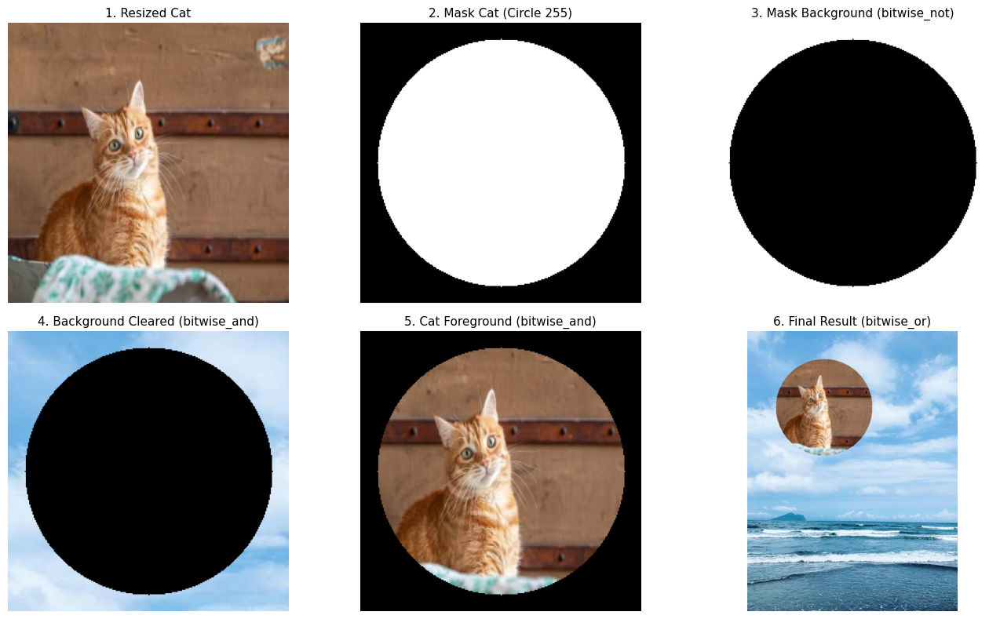

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. 讀取背景圖（海灘）與貓咪圖
img_bg = cv2.imread("background.jpg")
img_cat = cv2.imread("cat.jpg")  # 你的貓咪圖

# 2. 將貓咪圖縮小為正方形（例如 250x250），方便做圓形合成
size = 250
img_cat = cv2.resize(img_cat, (size, size), interpolation=cv2.INTER_AREA)

# 3. 取得放置位置 (ROI)
offset_y, offset_x = 50, 50
roi = img_bg[offset_y : offset_y + size, offset_x : offset_x + size]

# =========================================================
# 4. 製作正確的遮罩 (Mask)
# 建立一個圓形遮罩：圓形區域為白色(255)，其餘為黑色(0)
# =========================================================
mask_fg = np.zeros((size, size), dtype=np.uint8)
cv2.circle(mask_fg, (size // 2, size // 2), radius=110, color=255, thickness=-1)

# 5. cv2.bitwise_not: 製作反向遮罩 (圓形變黑 0，外面變白 255)
# 用於背景挖洞！
mask_bg = cv2.bitwise_not(mask_fg)

# 6. cv2.bitwise_and: 在背景挖出圓形黑洞
# 只有 mask_bg 為白色的地方保留海景，圓形為黑色的地方被清空成 (0, 0, 0)
img_bg_cleared = cv2.bitwise_and(roi, roi, mask=mask_bg)

# 7. cv2.bitwise_and: 萃取圓形貓咪
# 只有 mask_fg 為白色的圓形區域保留貓咪，圓形外變成黑底 (0, 0, 0)
img_cat_fg = cv2.bitwise_and(img_cat, img_cat, mask=mask_fg)

# 8. cv2.bitwise_or: 無痕拼接 (挖空背景 OR 圓形貓咪)
dst = cv2.bitwise_or(img_bg_cleared, img_cat_fg)

# 9. 貼回大背景圖
img_bg_final = img_bg.copy()
img_bg_final[offset_y : offset_y + size, offset_x : offset_x + size] = dst

# ==========================================
# 10. Matplotlib 視覺化呈現
# ==========================================
titles = [
    "1. Resized Cat",
    "2. Mask Cat (Circle 255)",
    "3. Mask Background (bitwise_not)",
    "4. Background Cleared (bitwise_and)",
    "5. Cat Foreground (bitwise_and)",
    "6. Final Result (bitwise_or)",
]

images = [
    cv2.cvtColor(img_cat, cv2.COLOR_BGR2RGB),
    mask_fg,
    mask_bg,
    cv2.cvtColor(img_bg_cleared, cv2.COLOR_BGR2RGB),
    cv2.cvtColor(img_cat_fg, cv2.COLOR_BGR2RGB),
    cv2.cvtColor(img_bg_final, cv2.COLOR_BGR2RGB),
]

plt.figure(figsize=(14, 8))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    if len(images[i].shape) == 2:
        plt.imshow(images[i], cmap="gray")
    else:
        plt.imshow(images[i])
    plt.title(titles[i], fontsize=11)
    plt.axis("off")

plt.tight_layout()
plt.show()
